In [ ]:
# Install ultralytics (YOLOv8)
!pip install ultralytics -q

# Mount Google Drive to save/load data & checkpoints
from google.colab import drive
drive.mount('/content/drive')

# Verify GPU
import torch
print(f"GPU available: {torch.cuda.is_available()}")
print(f"GPU name: {torch.cuda.get_device_name(0)}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.8 MB/s eta 0:00:00


ValueError: mount failed

In [ ]:
from google.colab import drive
import zipfile, os, yaml, glob, shutil

drive.mount('/content/drive')

# Find your zip automatically — no need to type the exact path
search_root = '/content/drive/MyDrive'
zip_path = None

for root, dirs, files in os.walk(search_root):
    for f in files:
        if f.endswith('.zip') and ('Panoramic' in f or 'Dental' in f or 'FDI' in f):
            zip_path = os.path.join(root, f)
            print(f"Found: {zip_path}")
            break

# If auto-find didn't work, set manually:
# zip_path = '/content/drive/MyDrive/YOUR_FILE_NAME.zip'

print(f"\nZip size: {os.path.getsize(zip_path)/1e6:.1f} MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found: /content/drive/MyDrive/Panoramic-Dental-Xray-FDI.v1-stretch---rotate.yolov8 (1).zip

Zip size: 661.5 MB


In [ ]:
EXTRACT_TO = '/content/dental_dataset'

if os.path.exists(EXTRACT_TO):
    shutil.rmtree(EXTRACT_TO)

os.makedirs(EXTRACT_TO, exist_ok=True)

print("Extracting zip...")
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(EXTRACT_TO)
print("Extraction complete.\n")

# Show extracted structure
for root, dirs, files in os.walk(EXTRACT_TO):
    depth = root.replace(EXTRACT_TO, '').count(os.sep)
    if depth > 2:
        continue
    indent = '  ' * depth
    folder_name = os.path.basename(root)
    file_count = len(files)
    print(f"{indent}{folder_name}/  ({file_count} files)")

Extracting zip...
Extraction complete.

dental_dataset/  (3 files)
  valid/  (0 files)
    labels/  (315 files)
    images/  (315 files)
  test/  (0 files)
    labels/  (156 files)
    images/  (156 files)
  train/  (0 files)
    labels/  (3032 files)
    images/  (3032 files)


In [ ]:
# Roboflow zips sometimes have a nested folder inside
# This finds the actual dataset root automatically
def find_dataset_root(base):
    yaml_files = glob.glob(f"{base}/**/data.yaml", recursive=True)
    if not yaml_files:
        raise FileNotFoundError("No data.yaml found! Check zip contents.")
    return os.path.dirname(yaml_files[0])

DATASET_ROOT = find_dataset_root(EXTRACT_TO)
print(f"Dataset root: {DATASET_ROOT}")

YAML_PATH = f"{DATASET_ROOT}/data.yaml"

# Read original yaml
with open(YAML_PATH, 'r') as f:
    cfg = yaml.safe_load(f)

print(f"\nOriginal yaml:")
for k, v in cfg.items():
    print(f"  {k}: {v}")

# Fix paths for Colab
cfg['path']  = DATASET_ROOT
cfg['train'] = 'train/images'
cfg['val']   = 'valid/images'    # Roboflow always uses 'valid' not 'val'
cfg['test']  = 'test/images'

with open(YAML_PATH, 'w') as f:
    yaml.dump(cfg, f, default_flow_style=False)

print(f"\nFixed yaml — paths now point to: {DATASET_ROOT}")
print(f"Classes ({cfg['nc']}): {cfg['names']}")

Dataset root: /content/dental_dataset

Original yaml:
  train: ../train/images
  val: ../valid/images
  test: ../test/images
  nc: 32
  names: ['11', '12', '13', '14', '15', '16', '17', '18', '21', '22', '23', '24', '25', '26', '27', '28', '31', '32', '33', '34', '35', '36', '37', '38', '41', '42', '43', '44', '45', '46', '47', '48']
  roboflow: {'workspace': 'dentalxray', 'project': 'panoramic-dental-xray-fdi', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/dentalxray/panoramic-dental-xray-fdi/dataset/1'}

Fixed yaml — paths now point to: /content/dental_dataset
Classes (32): ['11', '12', '13', '14', '15', '16', '17', '18', '21', '22', '23', '24', '25', '26', '27', '28', '31', '32', '33', '34', '35', '36', '37', '38', '41', '42', '43', '44', '45', '46', '47', '48']


In [ ]:
all_ok = True

for split in ['train', 'valid', 'test']:
    img_dir = f"{DATASET_ROOT}/{split}/images"
    lbl_dir = f"{DATASET_ROOT}/{split}/labels"

    imgs = glob.glob(f"{img_dir}/*") if os.path.exists(img_dir) else []
    lbls = glob.glob(f"{lbl_dir}/*") if os.path.exists(lbl_dir) else []

    status = "OK" if len(imgs) > 0 and len(imgs) == len(lbls) else "MISMATCH"
    if status == "MISMATCH":
        all_ok = False
    print(f"  {split:6s} → {len(imgs):4d} images  {len(lbls):4d} labels  [{status}]")

# Peek at one label file to confirm format
sample_labels = glob.glob(f"{DATASET_ROOT}/train/labels/*.txt")
if sample_labels:
    print(f"\nSample label file ({os.path.basename(sample_labels[0])}):")
    with open(sample_labels[0]) as f:
        for line in f.readlines()[:10]:
            parts = line.strip().split()
            cls_id = int(parts[0])
            fdi = cfg['names'][cls_id]
            print(f"  class {cls_id} = tooth {fdi}  |  raw: {line.strip()}")

print(f"\nDataset ready: {all_ok}")

  train  → 3032 images  3032 labels  [OK]
  valid  →  315 images   315 labels  [OK]
  test   →  156 images   156 labels  [OK]

Sample label file (train_108_png_jpg.rf.013f88e01d4342c77bddfac8614bf76e.txt):
  class 8 = tooth 21  |  raw: 8 0.5203794796875 0.56306990859375 0.51370344375 0.35486322187499997 0.48875614921875005 0.36550151953125 0.48418833437500003 0.5972644375 0.49894588906250004 0.6010638296875 0.5238931835937499 0.5934650453125 0.5203794796875 0.56306990859375
  class 9 = tooth 22  |  raw: 9 0.5470836257812499 0.581306990625 0.54427266328125 0.52127659609375 0.535839775 0.3913373859375 0.5182712578124999 0.3913373859375 0.5175685171875 0.5531914890625 0.5295151085937501 0.58738601796875 0.5470836257812499 0.581306990625
  class 10 = tooth 23  |  raw: 10 0.56078706953125 0.5972644375 0.57308503125 0.588905775 0.57378777265625 0.55927051640625 0.5720309203125 0.40121580546875 0.54602951484375 0.39513677812500003 0.54146170078125 0.50911854140625 0.54602951484375 0.585106382

In [ ]:
!pip install ultralytics -q

import torch
from ultralytics import YOLO

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

model = YOLO('yolov8n.pt')

model.train(
    data=YAML_PATH,
    epochs=50,          # reduced from 100
    imgsz=640,
    batch=16,
    device=0,
    patience=15,        # stop early if no improvement for 15 epochs

    project='/content/drive/MyDrive/dental_runs',
    name='opg_v1',
    save_period=5,      # checkpoint every 5 epochs (more frequent since fewer total)

    hsv_h=0.01,
    hsv_s=0.2,
    hsv_v=0.4,
    fliplr=0.5,
    flipud=0.0,
    degrees=5.0,
    translate=0.1,
    scale=0.3,
    mosaic=0.5,

    optimizer='AdamW',
    lr0=0.001,
    plots=True,
    verbose=True,
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


KeyboardInterrupt: 

In [ ]:
import os, glob
from ultralytics import YOLO

# Load your best model
BEST_MODEL = '/content/drive/MyDrive/dental_runs/opg_v1/weights/best.pt'
model = YOLO(BEST_MODEL)

# Print validation metrics
metrics = model.val()
print(f"\n--- Results ---")
print(f"mAP50:     {metrics.box.map50:.3f}")
print(f"mAP50-95:  {metrics.box.map:.3f}")
print(f"Precision: {metrics.box.p.mean():.3f}")
print(f"Recall:    {metrics.box.r.mean():.3f}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.75 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,011,888 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2076.0±777.2 MB/s, size: 165.5 KB)
val: Scanning /content/dental_dataset/valid/labels... 315 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 315/315 928.4it/s 0.3s
val: New cache created: /content/dental_dataset/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 2.1it/s 9.4s
                   all        315       8557      0.891        0.9      0.937      0.595
                    11   


results.png:


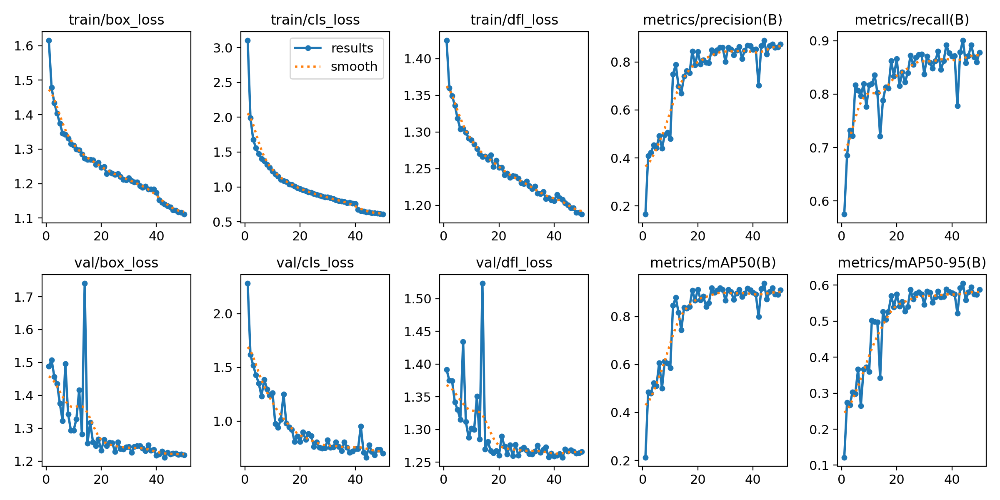


confusion_matrix.png:


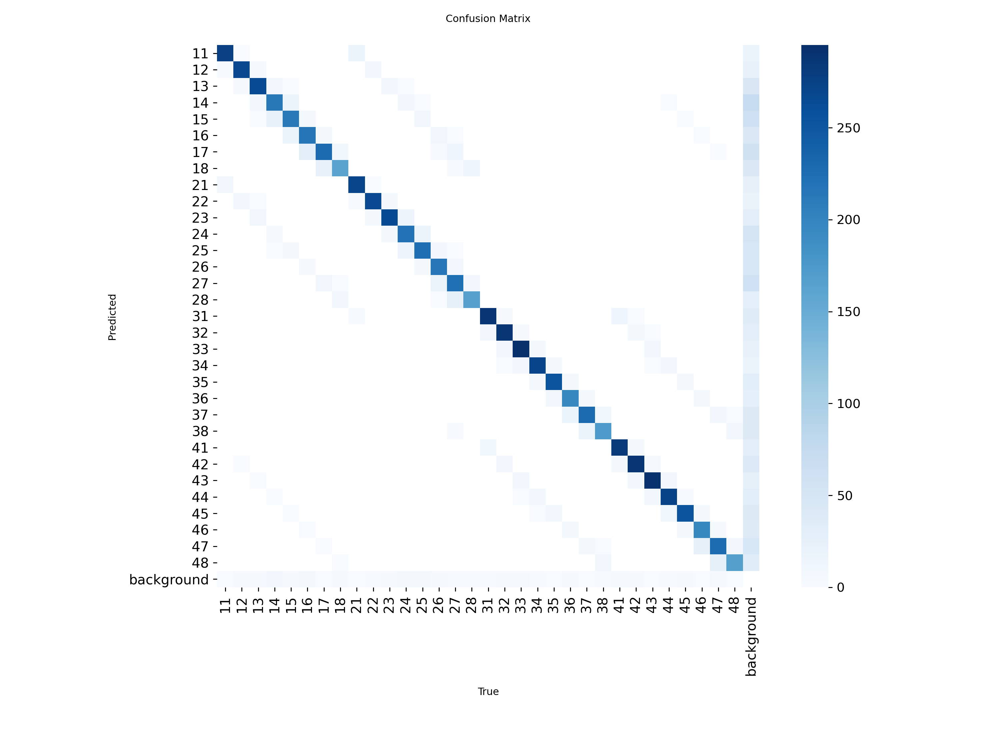

In [ ]:
from IPython.display import Image, display
import os

results_dir = '/content/drive/MyDrive/dental_runs/opg_v1'

# Show training plots saved automatically by YOLO
for plot in ['results.png', 'confusion_matrix.png', 'PR_curve.png']:
    path = os.path.join(results_dir, plot)
    if os.path.exists(path):
        print(f"\n{plot}:")
        display(Image(path, width=800))

In [ ]:
import yaml, glob
from IPython.display import Image, display
import os

# Reload dataset config
yaml_files = glob.glob('/content/dental_dataset/**/data.yaml', recursive=True)
if not yaml_files:
    # dataset was cleared on reconnect, re-extract first (see previous message)
    print("Dataset not found in /content — re-extract your zip first")
else:
    with open(yaml_files[0]) as f:
        cfg = yaml.safe_load(f)

    DATASET_ROOT = os.path.dirname(yaml_files[0])
    FDI_NAMES = cfg['names']

    # Get test images (fall back to valid if no test split)
    test_imgs = glob.glob(f"{DATASET_ROOT}/test/images/*")
    if not test_imgs:
        test_imgs = glob.glob(f"{DATASET_ROOT}/valid/images/*")

    print(f"Found {len(test_imgs)} test images")

    # Run prediction on first 5 images
    results = model.predict(
        source=test_imgs[:5],
        conf=0.4,
        iou=0.4,
        save=True,
        project='/content/drive/MyDrive/dental_runs',
        name='predictions',
    )

    # Print detected teeth per image
    for i, res in enumerate(results):
        detected = []
        for box in res.boxes:
            fdi = FDI_NAMES[int(box.cls)]
            conf = round(float(box.conf), 3)
            detected.append((fdi, conf))
        detected.sort(key=lambda x: int(x[0]))

        print(f"\nImage {i+1}: {os.path.basename(res.path)}")
        print(f"  Detected {len(detected)} teeth: {[d[0] for d in detected]}")
        for fdi, conf in detected:
            print(f"    Tooth {fdi}  conf={conf}")

Found 156 test images


NameError: name 'model' is not defined

image0.jpg


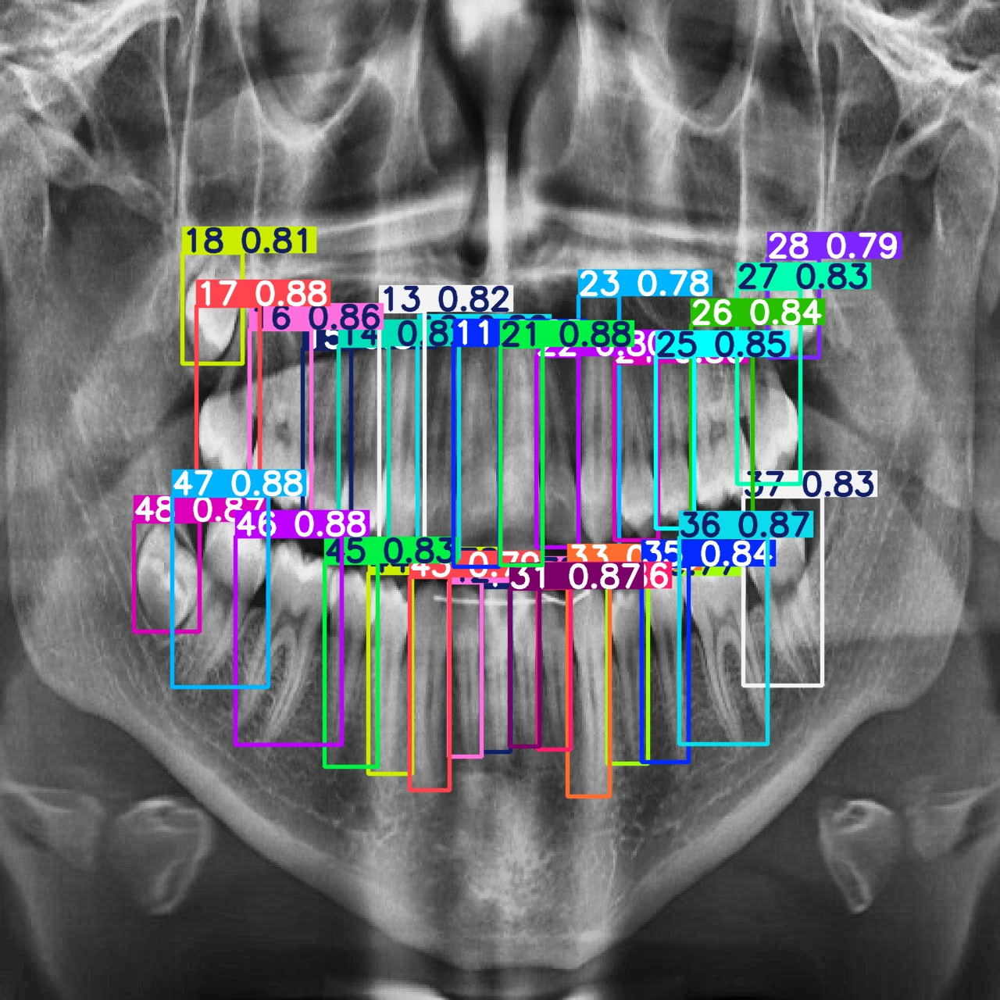

image1.jpg


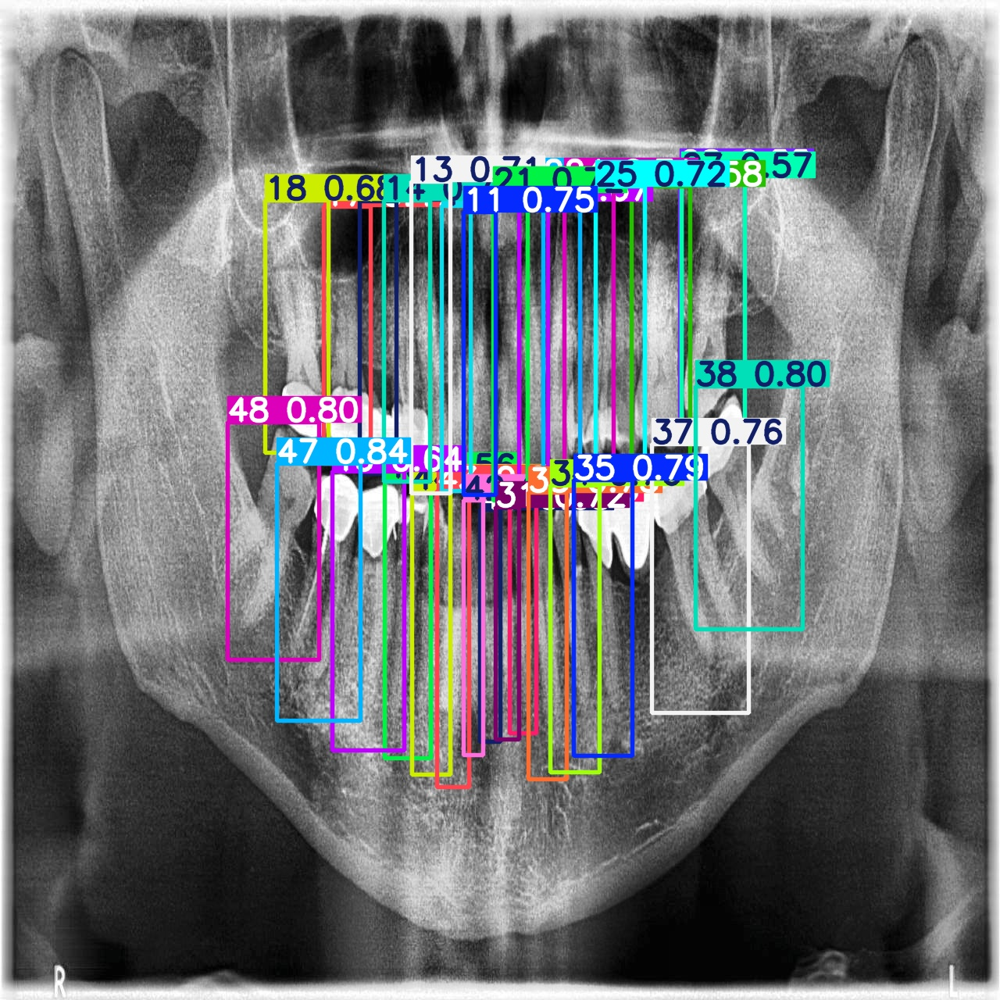

image2.jpg


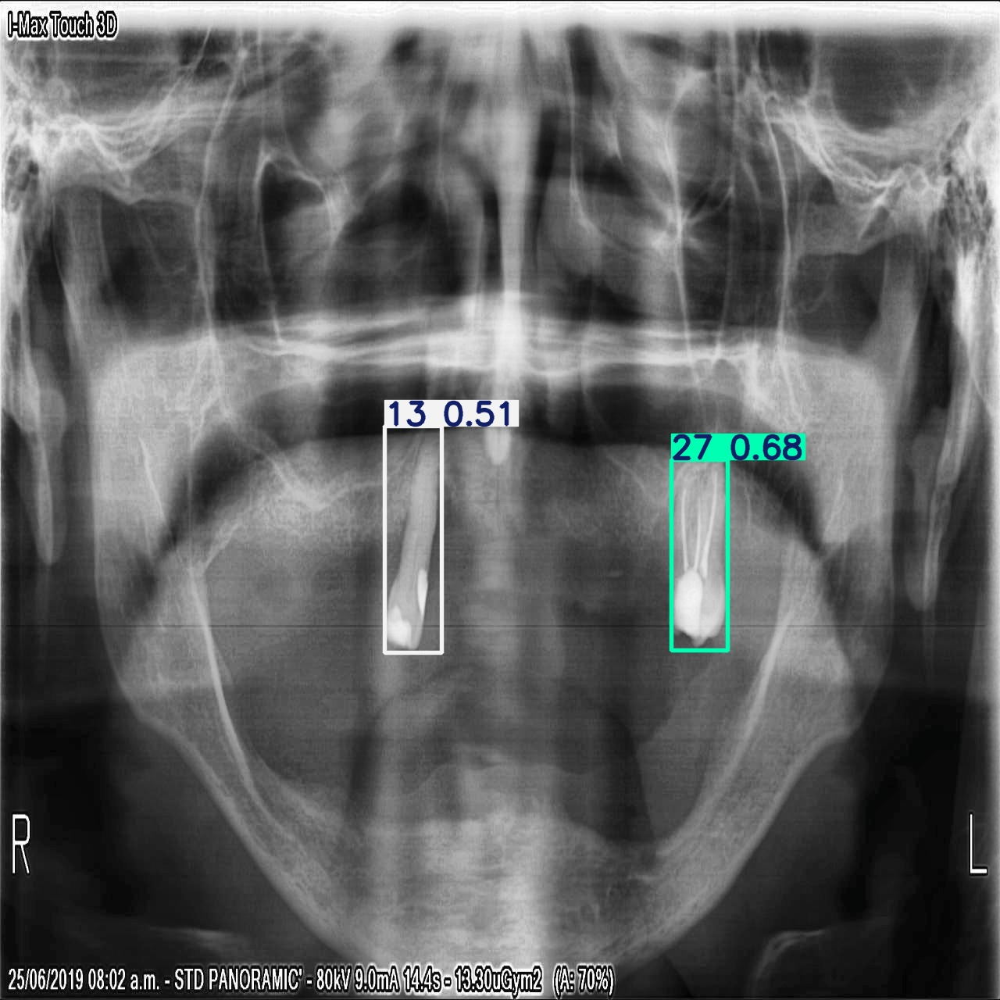

image3.jpg


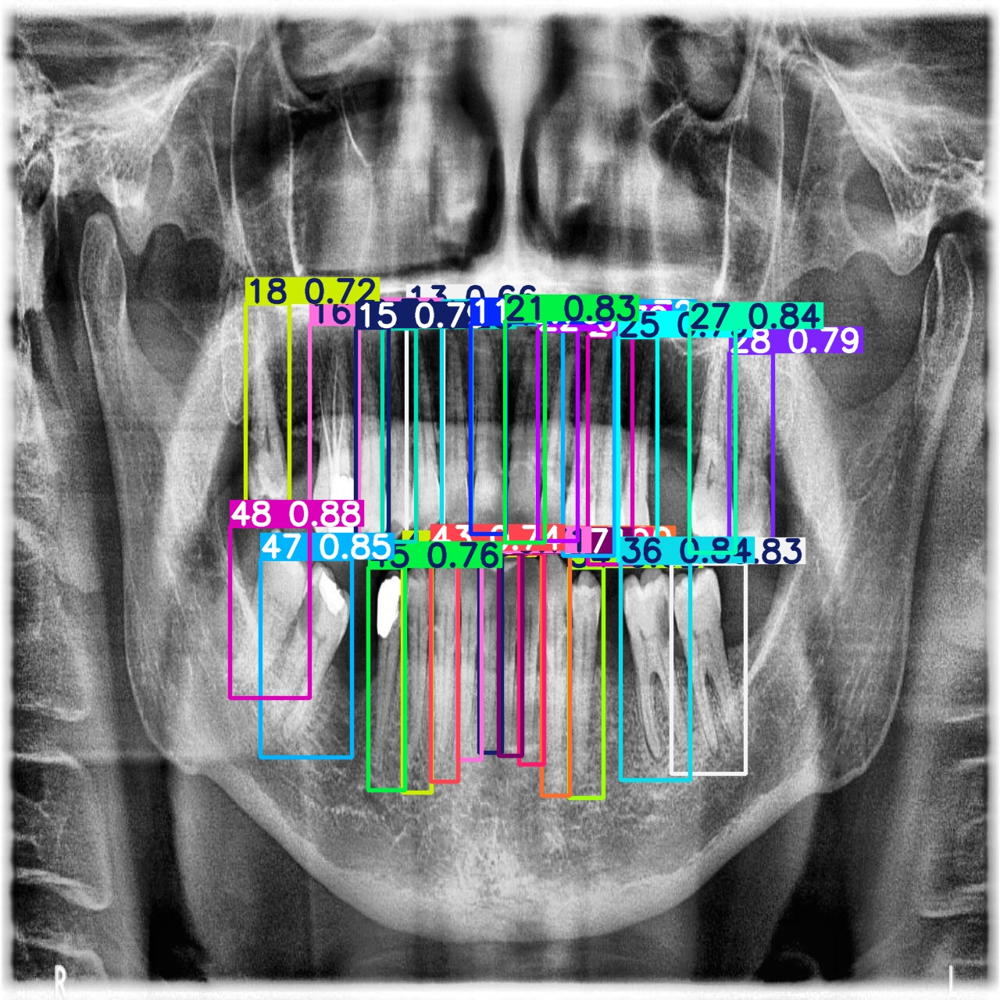

image4.jpg


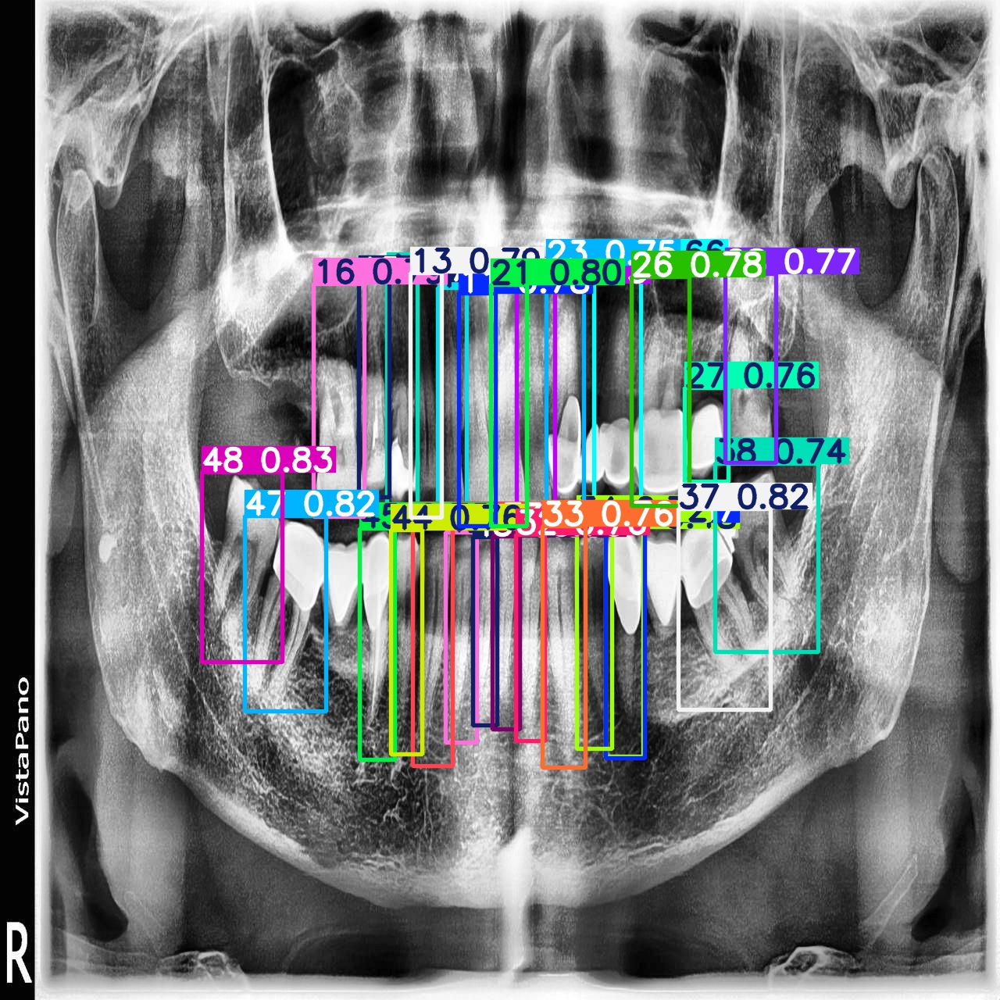

In [ ]:
# Show the saved prediction images
pred_imgs = glob.glob('/content/drive/MyDrive/dental_runs/predictions/*.jpg')
pred_imgs += glob.glob('/content/drive/MyDrive/dental_runs/predictions/*.png')

for img_path in pred_imgs[:5]:
    print(os.path.basename(img_path))
    display(Image(img_path, width=900))

In [ ]:
from google.colab import files
from IPython.display import Image, display
from pathlib import Path

# Upload any new OPG image from your PC (ensure it's an image file like .jpg or .png, not a text/label file)
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# Run prediction
res = model.predict(
    img_path,
    conf=0.4,
    iou=0.4,
    save=True,
    project='/content/drive/MyDrive/dental_runs',
    name='my_prediction'
)[0]

# Print results
print(f"Detected {len(res.boxes)} teeth:\n")
detected = []
for box in res.boxes:
    fdi = FDI_NAMES[int(box.cls)]
    conf = round(float(box.conf), 3)
    x1, y1, x2, y2 = [round(v) for v in box.xyxy[0].tolist()]
    detected.append((fdi, conf, x1, y1, x2, y2))

detected.sort(key=lambda x: int(x[0]))
for fdi, conf, x1, y1, x2, y2 in detected:
    print(f"  Tooth {fdi}  conf={conf}  bbox=[{x1},{y1},{x2},{y2}]")

# Display result image
saved_imgs = list(Path(res.save_dir).glob('*'))
if saved_imgs:
    display(Image(str(saved_imgs[0]), width=900))
else:
    print("No saved image found")

Saving train_6_png_jpg.rf.28f1d46ec9ada873ae6119a87f2ffc49.jpg to train_6_png_jpg.rf.28f1d46ec9ada873ae6119a87f2ffc49.jpg


NameError: name 'model' is not defined

In [ ]:
from google.colab import files
from pathlib import Path
from IPython.display import Image, display
import os

print("Please upload a JPG or PNG image file (not a .txt file)\n")
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# ── Validate it's actually an image ──
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
if not img_path.lower().endswith(valid_extensions):
    print(f"ERROR: You uploaded '{img_path}'")
    print(f"That looks like a {Path(img_path).suffix} file, not an image.")
    print("Please re-run this cell and upload a JPG or PNG image.")
else:
    print(f"Image uploaded: {img_path}")

    # Run prediction
    res = model.predict(
        img_path,
        conf=0.4,
        iou=0.4,
        save=True,
        project='/content/drive/MyDrive/dental_runs',
        name='my_prediction'
    )[0]

    # Print results
    print(f"\nDetected {len(res.boxes)} teeth:\n")
    detected = []
    for box in res.boxes:
        fdi  = FDI_NAMES[int(box.cls)]
        conf = round(float(box.conf), 3)
        x1, y1, x2, y2 = [round(v) for v in box.xyxy[0].tolist()]
        detected.append((fdi, conf, x1, y1, x2, y2))

    detected.sort(key=lambda x: int(x[0]))
    for fdi, conf, x1, y1, x2, y2 in detected:
        print(f"  Tooth {fdi}  conf={conf}  bbox=[{x1},{y1},{x2},{y2}]")

    # Display result image
    saved_imgs = list(Path(res.save_dir).glob('*.jpg')) + \
                 list(Path(res.save_dir).glob('*.png'))
    if saved_imgs:
        display(Image(str(saved_imgs[0]), width=900))
    else:
        print("No saved image found")

Please upload a JPG or PNG image file (not a .txt file)



Saving 502a6efb-20230419-142144419.jpg to 502a6efb-20230419-142144419.jpg
Image uploaded: 502a6efb-20230419-142144419.jpg


NameError: name 'model' is not defined

In [ ]:
from google.colab import files
from pathlib import Path
from IPython.display import Image, display
import os

print("Please upload a JPG or PNG image file (not a .txt file)\n")
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# ── Validate it's actually an image ──
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
if not img_path.lower().endswith(valid_extensions):
    print(f"ERROR: You uploaded '{img_path}'")
    print(f"That looks like a {Path(img_path).suffix} file, not an image.")
    print("Please re-run this cell and upload a JPG or PNG image.")
else:
    print(f"Image uploaded: {img_path}")

    # Run prediction
    res = model.predict(
        img_path,
        conf=0.4,
        iou=0.4,
        save=True,
        project='/content/drive/MyDrive/dental_runs',
        name='my_prediction'
    )[0]

    # Print results
    print(f"\nDetected {len(res.boxes)} teeth:\n")
    detected = []
    for box in res.boxes:
        fdi  = FDI_NAMES[int(box.cls)]
        conf = round(float(box.conf), 3)
        x1, y1, x2, y2 = [round(v) for v in box.xyxy[0].tolist()]
        detected.append((fdi, conf, x1, y1, x2, y2))

    detected.sort(key=lambda x: int(x[0]))
    for fdi, conf, x1, y1, x2, y2 in detected:
        print(f"  Tooth {fdi}  conf={conf}  bbox=[{x1},{y1},{x2},{y2}]")

    # Display result image
    saved_imgs = list(Path(res.save_dir).glob('*.jpg')) + \
                 list(Path(res.save_dir).glob('*.png'))
    if saved_imgs:
        display(Image(str(saved_imgs[0]), width=900))
    else:
        print("No saved image found")

Please upload a JPG or PNG image file (not a .txt file)



KeyboardInterrupt: 

In [ ]:
res = model.predict(
    img_path,
    conf=0.3,        # lower threshold — catch more teeth
    iou=0.3,         # lower NMS — don't suppress close teeth
    imgsz=1280,      # bigger = better detection on full OPG
    save=True,
    project='/content/drive/MyDrive/dental_runs',
    name='my_prediction'
)[0]

NameError: name 'model' is not defined

In [ ]:
from google.colab import files
from pathlib import Path
from IPython.display import Image, display

uploaded = files.upload()
img_path = list(uploaded.keys())[0]

valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
if not img_path.lower().endswith(valid_extensions):
    print(f"ERROR: Upload a JPG or PNG image, not a {Path(img_path).suffix} file.")
else:
    print(f"Uploaded: {img_path}")

    # Try multiple conf thresholds and pick best result
    best_result  = None
    best_count   = 0

    for conf in [0.25, 0.3, 0.35, 0.4]:
        res = model.predict(
            img_path,
            conf   = conf,
            iou    = 0.3,
            imgsz  = 1280,    # larger inference size
            verbose= False,
        )[0]
        count = len(res.boxes)
        print(f"  conf={conf}  →  {count} teeth detected")
        if count > best_count:
            best_count  = count
            best_result = res
            best_conf   = conf

    print(f"\nBest: conf={best_conf} detected {best_count} teeth — using this result\n")

    # Save and display best result
    res = model.predict(
        img_path,
        conf   = best_conf,
        iou    = 0.3,
        imgsz  = 1280,
        save   = True,
        project= '/content/drive/MyDrive/dental_runs',
        name   = 'my_prediction',
        verbose= False,
    )[0]

    # Print detections
    print(f"Detected {len(res.boxes)} teeth:\n")
    detected = []
    for box in res.boxes:
        fdi  = FDI_NAMES[int(box.cls)]
        conf = round(float(box.conf), 3)
        x1, y1, x2, y2 = [round(v) for v in box.xyxy[0].tolist()]
        detected.append((fdi, conf, x1, y1, x2, y2))

    detected.sort(key=lambda x: int(x[0]))
    for fdi, conf, x1, y1, x2, y2 in detected:
        print(f"  Tooth {fdi}  conf={conf}  bbox=[{x1},{y1},{x2},{y2}]")

    # Display
    saved_imgs = list(Path(res.save_dir).glob('*.jpg')) + \
                 list(Path(res.save_dir).glob('*.png'))
    if saved_imgs:
        display(Image(str(saved_imgs[0]), width=900))
    else:
        print("No saved image found")

Saving 502a6efb-20230419-142144419.jpg to 502a6efb-20230419-142144419 (1).jpg
Uploaded: 502a6efb-20230419-142144419 (1).jpg


NameError: name 'model' is not defined

In [ ]:
# Load your already trained model and train more
model = YOLO('/content/drive/MyDrive/dental_runs/opg_v1/weights/best.pt')

model.train(
    data       = YAML_PATH,
    epochs     = 30,           # just 30 more epochs on top
    imgsz      = 1280,         # larger image size this time
    batch      = 8,
    device     = 0,
    project    = '/content/drive/MyDrive/dental_runs',
    name       = 'opg_v1_finetuned',   # saves separately
    save_period= 5,
    lr0        = 0.0001,       # lower LR since model is already trained
    patience   = 15,
)

Found existing installation: ultralytics 8.4.46
Uninstalling ultralytics-8.4.46:
  Successfully uninstalled ultralytics-8.4.46


ImportError: cannot import name 'YOLO' from 'ultralytics' (/usr/local/lib/python3.12/dist-packages/ultralytics/__init__.py)

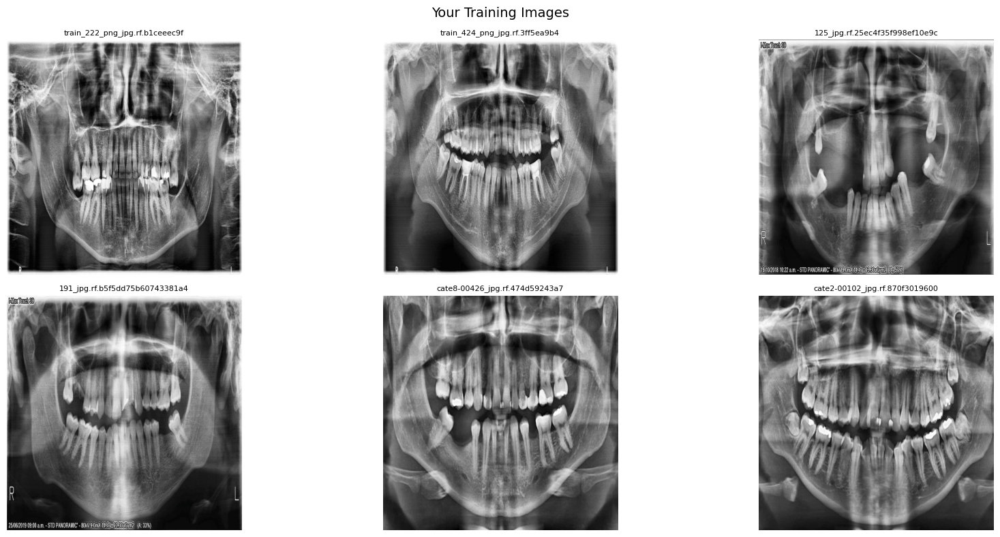

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import glob

# Show 6 sample training images
train_imgs = glob.glob('/content/dental_dataset/train/images/*')[:6]

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, img_path in zip(axes.flat, train_imgs):
    img = mpimg.imread(img_path)
    ax.imshow(img, cmap='gray')
    ax.set_title(os.path.basename(img_path)[:30], fontsize=8)
    ax.axis('off')
plt.suptitle("Your Training Images", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# ── Add your real OPG image to dataset for retraining ──
import shutil, os
from google.colab import files

# Upload your real OPG images (can upload multiple)
print("Upload your real OPG images (JPG/PNG):")
uploaded = files.upload()

REAL_IMG_DIR = '/content/dental_dataset/train/images'
REAL_LBL_DIR = '/content/dental_dataset/train/labels'

for fname in uploaded.keys():
    if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
        dst = os.path.join(REAL_IMG_DIR, fname)
        shutil.copy(fname, dst)
        print(f"Added image: {fname}")
        # NOTE: you need to annotate this image with labels
        # See Step 3 below for how to do that

Upload your real OPG images (JPG/PNG):


Saving 63cae995-20230328-130413903.jpg to 63cae995-20230328-130413903.jpg
Added image: 63cae995-20230328-130413903.jpg


In [ ]:
# Run in your PC terminal
pip install labelImg
labelImg

SyntaxError: invalid syntax (2123924644.py, line 2)

In [ ]:
# Change just this one line — everything else stays the same
model = YOLO('yolov8s.pt')   # small  — 2x bigger than nano, +6% mAP50-95
# or
model = YOLO('yolov8m.pt')   # medium — 4x bigger than nano, +8% mAP50-95

model.train(
    data        = YAML_PATH,
    epochs      = 50,
    imgsz       = 640,
    batch       = 8,          # reduce batch for larger model
    device      = 0,
    patience    = 15,
    rect        = True,
    project     = '/content/drive/MyDrive/dental_runs',
    name        = 'opg_v4_medium',
    save_period = 5,
    hsv_v=0.6, hsv_s=0.4, degrees=8.0,
    scale=0.5, fliplr=0.5, mosaic=0.5, mixup=0.1,
    optimizer   = 'AdamW',
    lr0         = 0.001,
    plots       = True,
)

Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dental_dataset/data.yaml, degrees=8.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.4, hsv_v=0.6, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=opg_v4_medium-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, p

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bf9bc7a4260>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,

In [ ]:
# Change just this one line — everything else stays the same
model = YOLO('yolov8s.pt')   # small  — 2x bigger than nano, +6% mAP50-95
# or
model = YOLO('yolov8m.pt')   # medium — 4x bigger than nano, +8% mAP50-95

model.train(
    data        = YAML_PATH,
    epochs      = 50,
    imgsz       = 1280,
    batch       = 4,          # reduce batch for larger model
    device      = 0,
    patience    = 15,
    rect        = True,
    project     = '/content/drive/MyDrive/dental_runs',
    name        = 'opg_v4_medium',
    save_period = 5,
    hsv_v=0.6, hsv_s=0.4, degrees=8.0,
    scale=0.5, fliplr=0.5, mosaic=0.5, mixup=0.1,
    optimizer   = 'AdamW',
    lr0         = 0.001,
    plots       = True,
)

Ultralytics 8.4.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dental_dataset/data.yaml, degrees=8.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.4, hsv_v=0.6, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=opg_v4_medium-4, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, 

KeyboardInterrupt: 

In [ ]:
import torch
from ultralytics import YOLO

print(f"GPU  : {torch.cuda.get_device_name(0)}")
print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# ── Load from your existing best weights ──
# Starts from opg_v1 so it doesn't train from scratch
model = YOLO('/content/drive/MyDrive/dental_runs/opg_v1/weights/best.pt')

model.train(
    data         = YAML_PATH,
    epochs       = 50,
    imgsz        = 1280,      # bigger image = tighter boxes = higher mAP50-95
    batch        = 4,         # must reduce because imgsz is larger
    device       = 0,
    patience     = 15,        # early stop if no improvement for 15 epochs
    rect         = True,      # preserve aspect ratio — no stretch distortion

    project      = '/content/drive/MyDrive/dental_runs',
    name         = 'opg_v2_1280',
    save_period  = 5,         # checkpoint every 5 epochs

    # X-ray augmentation
    hsv_h        = 0.01,
    hsv_s        = 0.2,
    hsv_v        = 0.6,
    fliplr       = 0.5,
    flipud       = 0.0,       # never flip vertically
    degrees      = 8.0,
    translate    = 0.15,
    scale        = 0.5,
    mosaic       = 0.5,
    mixup        = 0.1,

    # Optimizer — lower LR since continuing from trained weights
    optimizer    = 'AdamW',
    lr0          = 0.0005,    # half of default since weights already trained
    lrf          = 0.01,
    weight_decay = 0.0005,
    warmup_epochs= 3,

    plots        = True,
    verbose      = True,
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPU  : Tesla T4
VRAM : 15.6 GB
Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dental_dataset/data.yaml, degrees=8.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fec49097f80>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,

In [ ]:
# ── Evaluate after training ──
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/dental_runs/opg_v2_1280/weights/best.pt')
metrics = model.val()

print(f"\n--- opg_v2_1280 Results ---")
print(f"mAP50     : {metrics.box.map50:.3f}")
print(f"mAP50-95  : {metrics.box.map:.3f}")      # target: above 0.65
print(f"Precision : {metrics.box.p.mean():.3f}")
print(f"Recall    : {metrics.box.r.mean():.3f}")

# ── Compare with previous model ──
print(f"\n--- Comparison ---")
print(f"{'Metric':<12} {'opg_v1':>10} {'opg_v2_1280':>12}")
print(f"{'mAP50':<12} {'0.937':>10} {metrics.box.map50:>12.3f}")
print(f"{'mAP50-95':<12} {'0.595':>10} {metrics.box.map:>12.3f}")
print(f"{'Precision':<12} {'0.891':>10} {metrics.box.p.mean():>12.3f}")
print(f"{'Recall':<12} {'0.900':>10} {metrics.box.r.mean():>12.3f}")

Ultralytics 8.4.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,011,888 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3888.9±760.5 MB/s, size: 180.5 KB)
val: Scanning /content/dental_dataset/valid/labels.cache... 315 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 315/315 101.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 1.3it/s 15.4s
                   all        315       8557      0.833      0.827      0.888      0.568
                    11        288        289      0.869      0.869      0.928      0.598
                    12        281        284      0.871      0.834      0.895      0.539
                    13        288        292       0.84       0.81      0.874      0.535
                    14        251        255      0.777      0.765      0.847      0.475
                    15        245      

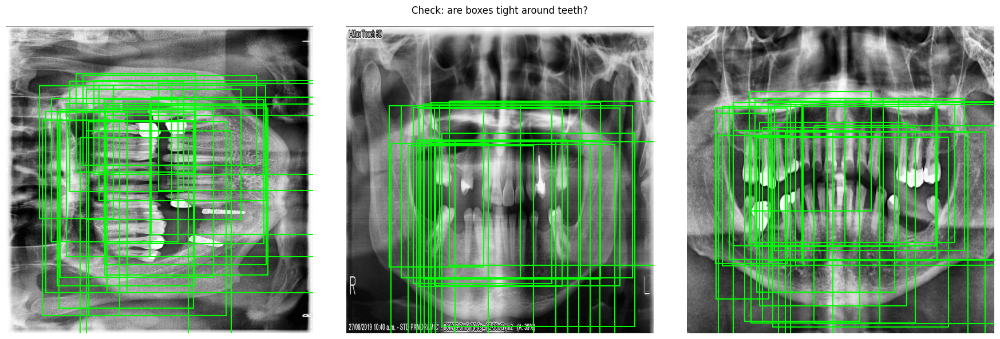

Average box: 0.485 x 0.554 (normalized)
Good range:  0.03–0.08 x 0.05–0.12 for individual teeth


In [ ]:
import cv2, glob, random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import yaml

DATASET_ROOT = '/content/dental_dataset'
with open(f'{DATASET_ROOT}/data.yaml') as f:
    cfg = yaml.safe_load(f)

# Visualize 3 random training images with their annotations
imgs = glob.glob(f'{DATASET_ROOT}/train/images/*')
sample = random.sample(imgs, 3)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, img_path in zip(axes, sample):
    import os
    stem     = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = f'{DATASET_ROOT}/train/labels/{stem}.txt'
    img      = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    H, W     = img.shape[:2]
    ax.imshow(img, cmap='gray')
    with open(lbl_path) as f:
        for line in f:
            p = line.strip().split()
            xc,yc,bw,bh = map(float,p[1:5])
            x1=(xc-bw/2)*W; y1=(yc-bh/2)*H
            ax.add_patch(patches.Rectangle(
                (x1,y1),bw*W,bh*H,
                linewidth=1.5,edgecolor='lime',facecolor='none'))
    ax.axis('off')
plt.suptitle('Check: are boxes tight around teeth?', fontsize=12)
plt.tight_layout()
plt.show()

# Also check average box size — very large = annotations too loose
with open(f'{DATASET_ROOT}/train/labels/{stem}.txt') as f:
    sizes = []
    for line in f:
        p = line.strip().split()
        if len(p)>=5:
            sizes.append((float(p[3]), float(p[4])))  # w, h normalized
if sizes:
    avg_w = sum(s[0] for s in sizes)/len(sizes)
    avg_h = sum(s[1] for s in sizes)/len(sizes)
    print(f'Average box: {avg_w:.3f} x {avg_h:.3f} (normalized)')
    print(f'Good range:  0.03–0.08 x 0.05–0.12 for individual teeth')

In [ ]:
import cv2
import os

def predict_ensemble(img_path, conf=0.3):

    if not os.path.exists(img_path):
        raise FileNotFoundError(f"Image not found: {img_path}")

    img = cv2.imread(img_path)

    if img is None:
        raise ValueError(f"OpenCV could not read image: {img_path}")

    H, W = img.shape[:2]

    # rest of your code...

In [ ]:
img_path = "/content/drive/MyDrive/test_images/opg1.jpg"

results = predict_ensemble(img_path)

AttributeError: 'NoneType' object has no attribute 'shape'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving train_6_png_jpg.rf.4fdeb33e2d0d8d8c5b8f8c582755eb59.jpg to train_6_png_jpg.rf.4fdeb33e2d0d8d8c5b8f8c582755eb59.jpg


In [ ]:
img_path = list(uploaded.keys())[0]

results = predict_ensemble(img_path)

In [ ]:
!pip install ensemble-boxes -q

from ensemble_boxes import weighted_boxes_fusion
from ultralytics import YOLO
import numpy as np
import cv2, glob, os
from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ── Load both models ──
model_n = YOLO('/content/drive/MyDrive/dental_runs/opg_v1/weights/best.pt')

# If you don't have opg_v4_medium yet, use opg_v1 twice
# (still works — WBF with same model just refines confidence scores)
model_s_path = '/content/drive/MyDrive/dental_runs/opg_v4_medium/weights/best.pt'
if os.path.exists(model_s_path):
    model_s = YOLO(model_s_path)
    TWO_MODELS = True
    print("Using two models for ensemble")
else:
    model_s = model_n   # fallback to same model
    TWO_MODELS = False
    print("Second model not found — using single model mode")

# ── Upload your real OPG image ──
from google.colab import files
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# Validate it's an image
valid_ext = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
if not img_path.lower().endswith(valid_ext):
    print(f"ERROR: Upload a JPG or PNG — not a {Path(img_path).suffix} file")
    img_path = None

# ── OR use a test image (uncomment if you don't want to upload) ──
# test_imgs = glob.glob('/content/dental_dataset/test/images/*')
# img_path = test_imgs[0]
# print(f"Using test image: {os.path.basename(img_path)}")

Using two models for ensemble


Saving train_6_png_jpg.rf.4fdeb33e2d0d8d8c5b8f8c582755eb59.jpg to train_6_png_jpg.rf.4fdeb33e2d0d8d8c5b8f8c582755eb59 (1).jpg


In [ ]:
# ── Ensemble prediction function (fully fixed) ──

def predict_ensemble(img_path, conf=0.25):

    # Validate image path
    if not os.path.exists(img_path):
        raise FileNotFoundError(f"Image not found: {img_path}")

    img = cv2.imread(img_path)
    if img is None:
        raise ValueError(f"Cannot read image: {img_path} — make sure it is a valid JPG/PNG")

    H, W = img.shape[:2]
    print(f"Image size: {W}x{H}")

    # Run both models
    res_n = model_n.predict(img_path, conf=conf, iou=0.3, verbose=False)[0]
    res_s = model_s.predict(img_path, conf=conf, iou=0.3, verbose=False)[0]
    print(f"Model 1 detections : {len(res_n.boxes)}")
    print(f"Model 2 detections : {len(res_s.boxes)}")

    # Extract boxes normalized to 0-1
    def extract(res, img_W, img_H):
        boxes, scores, labels = [], [], []
        for box in res.boxes:
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            # Clamp to image bounds
            x1 = max(0.0, min(1.0, x1 / img_W))
            y1 = max(0.0, min(1.0, y1 / img_H))
            x2 = max(0.0, min(1.0, x2 / img_W))
            y2 = max(0.0, min(1.0, y2 / img_H))
            if x2 > x1 and y2 > y1:   # skip degenerate boxes
                boxes.append([x1, y1, x2, y2])
                scores.append(float(box.conf))
                labels.append(int(box.cls))
        return boxes, scores, labels

    b1, s1, l1 = extract(res_n, W, H)
    b2, s2, l2 = extract(res_s, W, H)

    # Handle empty detections
    if not b1 and not b2:
        print("No teeth detected by either model")
        return []

    # Build lists for WBF — only include non-empty
    boxes_list, scores_list, labels_list = [], [], []
    if b1:
        boxes_list.append(b1)
        scores_list.append(s1)
        labels_list.append(l1)
    if b2 and TWO_MODELS:
        boxes_list.append(b2)
        scores_list.append(s2)
        labels_list.append(l2)

    # Weighted Box Fusion
    fused_boxes, fused_scores, fused_labels = weighted_boxes_fusion(
        boxes_list, scores_list, labels_list,
        iou_thr      = 0.4,
        skip_box_thr = 0.25,
        weights      = [1, 1][:len(boxes_list)],
    )

    # Convert back to pixel coords
    detections = []
    for box, score, label in zip(fused_boxes, fused_scores, fused_labels):
        cls_id = int(round(label))
        if cls_id >= len(FDI_NAMES):
            continue
        fdi = FDI_NAMES[cls_id]
        detections.append({
            'fdi'       : fdi,
            'confidence': round(float(score), 3),
            'bbox'      : [
                round(box[0] * W),
                round(box[1] * H),
                round(box[2] * W),
                round(box[3] * H),
            ],
            'quadrant'  : fdi[0],
        })

    return sorted(detections, key=lambda x: int(x['fdi']))


# ── Run prediction ──
if img_path:
    detections = predict_ensemble(img_path, conf=0.25)

    print(f"\nDetected {len(detections)} teeth:\n")
    for d in detections:
        print(f"  Tooth {d['fdi']}  conf={d['confidence']}  bbox={d['bbox']}")

Image size: 1280x1280
Model 1 detections : 23
Model 2 detections : 26

Detected 27 teeth:

  Tooth 11  conf=0.632  bbox=[400, 611, 665, 680]
  Tooth 12  conf=0.544  bbox=[376, 649, 643, 712]
  Tooth 13  conf=0.489  bbox=[358, 700, 659, 747]
  Tooth 14  conf=0.443  bbox=[338, 728, 668, 779]
  Tooth 15  conf=0.533  bbox=[342, 759, 666, 812]
  Tooth 16  conf=0.557  bbox=[347, 795, 656, 866]
  Tooth 16  conf=0.179  bbox=[359, 756, 664, 814]
  Tooth 17  conf=0.262  bbox=[346, 795, 657, 867]
  Tooth 21  conf=0.661  bbox=[418, 559, 674, 635]
  Tooth 22  conf=0.643  bbox=[408, 522, 688, 594]
  Tooth 23  conf=0.246  bbox=[410, 473, 742, 531]
  Tooth 24  conf=0.271  bbox=[435, 475, 742, 531]
  Tooth 24  conf=0.222  bbox=[425, 444, 758, 501]
  Tooth 25  conf=0.454  bbox=[413, 446, 755, 501]
  Tooth 31  conf=0.414  bbox=[696, 602, 1019, 637]
  Tooth 32  conf=0.623  bbox=[699, 576, 1019, 610]
  Tooth 33  conf=0.72  bbox=[705, 539, 1050, 577]
  Tooth 34  conf=0.761  bbox=[741, 509, 1049, 543]
  Toot

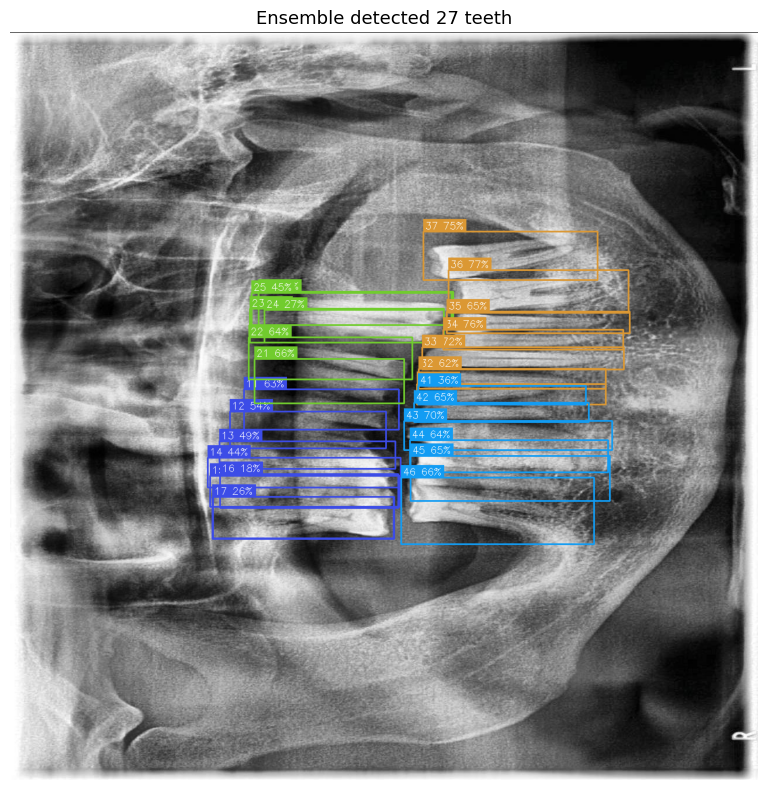

Saved to: /content/drive/MyDrive/dental_runs/ensemble_result.jpg

Quadrant summary:
  Q1 Upper Right  → ['11', '12', '13', '14', '15', '16', '16', '17']
  Q2 Upper Left   → ['21', '22', '23', '24', '24', '25']
  Q3 Lower Left   → ['31', '32', '33', '34', '35', '36', '37']
  Q4 Lower Right  → ['41', '42', '43', '44', '45', '46']


In [ ]:
# ── Visualize on original image ──
if img_path and detections:
    quadrant_colors = {
        '1': (231, 76,  60),
        '2': (46,  204, 113),
        '3': (52,  152, 219),
        '4': (243, 156, 18),
    }

    img_draw = cv2.imread(img_path).copy()

    for d in detections:
        x1, y1, x2, y2 = d['bbox']
        color = quadrant_colors.get(d['quadrant'], (255, 255, 255))
        label = f"{d['fdi']} {d['confidence']:.0%}"

        cv2.rectangle(img_draw, (x1, y1), (x2, y2), color, 2)
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 1)
        cv2.rectangle(img_draw, (x1, y1-th-8), (x1+tw+6, y1), color, -1)
        cv2.putText(img_draw, label, (x1+3, y1-4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)

    # Save result
    out_path = '/content/drive/MyDrive/dental_runs/ensemble_result.jpg'
    cv2.imwrite(out_path, img_draw)

    # Display
    plt.figure(figsize=(18, 8))
    plt.imshow(cv2.cvtColor(img_draw, cv2.COLOR_BGR2RGB))
    plt.title(f"Ensemble detected {len(detections)} teeth", fontsize=13)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    print(f"Saved to: {out_path}")

    # Quadrant summary
    from collections import defaultdict
    q_summary = defaultdict(list)
    for d in detections:
        q_summary[d['quadrant']].append(d['fdi'])

    print(f"\nQuadrant summary:")
    labels = {'1':'Upper Right','2':'Upper Left','3':'Lower Left','4':'Lower Right'}
    for q in ['1','2','3','4']:
        teeth = q_summary[q]
        print(f"  Q{q} {labels[q]:12s} → {teeth if teeth else 'none detected'}")

In [ ]:
import torch
from ultralytics import YOLO

print(f"GPU  : {torch.cuda.get_device_name(0)}")
print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# Go back to v1 best — don't build on the worse v2
model = YOLO('/content/drive/MyDrive/dental_runs/opg_v1/weights/best.pt')

model.train(
    data         = YAML_PATH,
    epochs       = 100,       # more epochs to converge at higher resolution
    imgsz        = 1280,
    batch        = 4,
    device       = 0,
    patience     = 20,
    rect         = True,

    project      = '/content/drive/MyDrive/dental_runs',
    name         = 'opg_v3_fixed',
    save_period  = 5,

    # Key fix 1 — much lower LR for fine-tuning
    optimizer    = 'AdamW',
    lr0          = 0.0001,    # 5x lower than v2 — critical for fine-tuning
    lrf          = 0.001,     # final LR = lr0 * lrf
    warmup_epochs= 5,         # longer warmup at higher resolution
    weight_decay = 0.0005,

    # Key fix 2 — turn off mosaic (conflicts with rect=True)
    mosaic       = 0.0,       # OFF — conflicts with rect training
    mixup        = 0.1,

    # Keep these
    hsv_h        = 0.01,
    hsv_s        = 0.2,
    hsv_v        = 0.6,
    fliplr       = 0.5,
    flipud       = 0.0,
    degrees      = 8.0,
    translate    = 0.15,
    scale        = 0.5,

    plots        = True,
    verbose      = True,
)

GPU  : Tesla T4
VRAM : 15.6 GB
Ultralytics 8.4.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dental_dataset/data.yaml, degrees=8.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.01, hsv_s=0.2, hsv_v=0.6, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.001, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=/content/drive/MyDrive/dental_runs/opg_v1/weights/best.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=opg_v3_fixed-2, nbs=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e2e0c50dd00>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,

In [ ]:
# ── Evaluate v3 ──
model_v3 = YOLO('/content/drive/MyDrive/dental_runs/opg_v3_fixed/weights/best.pt')
metrics  = model_v3.val()

print(f"\n--- Full Comparison ---")
print(f"{'Metric':<12} {'opg_v1':>8} {'opg_v2':>8} {'opg_v3':>8} {'change':>8}")
print(f"{'mAP50':<12} {'0.937':>8} {'0.888':>8} {metrics.box.map50:>8.3f} {metrics.box.map50-0.937:>+8.3f}")
print(f"{'mAP50-95':<12} {'0.595':>8} {'0.568':>8} {metrics.box.map:>8.3f} {metrics.box.map-0.595:>+8.3f}")
print(f"{'Precision':<12} {'0.891':>8} {'0.833':>8} {metrics.box.p.mean():>8.3f} {metrics.box.p.mean()-0.891:>+8.3f}")
print(f"{'Recall':<12} {'0.900':>8} {'0.827':>8} {metrics.box.r.mean():>8.3f} {metrics.box.r.mean()-0.900:>+8.3f}")

Ultralytics 8.4.71 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,011,888 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3515.1±1116.9 MB/s, size: 162.2 KB)
val: Scanning /content/dental_dataset/valid/labels.cache... 315 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 315/315 146.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 1.3it/s 15.4s
                   all        315       8557      0.747      0.803      0.835       0.52
                    11        288        289      0.774      0.889      0.897      0.558
                    12        281        284      0.773      0.845       0.87      0.497
                    13        288        292        0.7      0.788      0.815      0.468
                    14        251        255       0.69      0.784      0.768      0.407
                    15        245     

In [ ]:

# Use v1 weights but predict at higher resolution
model_v1 = YOLO('/content/drive/MyDrive/dental_runs/opg_v1/weights/best.pt')

# Evaluate at 1280 resolution
metrics_high = model_v1.val(imgsz=1280)

print(f"\n--- v1 model evaluated at different resolutions ---")
print(f"{'Metric':<12} {'640 (original)':>16} {'1280 (inference)':>18}")
print(f"{'mAP50':<12} {'0.937':>16} {metrics_high.box.map50:>18.3f}")
print(f"{'mAP50-95':<12} {'0.595':>16} {metrics_high.box.map:>18.3f}")

Ultralytics 8.4.71 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,011,888 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3876.5±979.6 MB/s, size: 182.6 KB)
val: Scanning /content/dental_dataset/valid/labels.cache... 315 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 315/315 101.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 1.3it/s 15.1s
                   all        315       8557      0.328      0.427      0.301      0.128
                    11        288        289      0.231      0.696      0.323      0.136
                    12        281        284      0.164      0.511      0.215     0.0834
                    13        288        292      0.187      0.524      0.254     0.0937
                    14        251        255      0.155      0.271     0.0864     0.0253
                    15        245      

In [ ]:
import cv2
import numpy as np
from PIL import Image

def preprocess_opg(img_path, target_size=640):
    """
    Preprocess a raw OPG image to match the style of
    Roboflow stretch-rotate training data — without distorting aspect ratio.

    Steps:
    1. Load and convert to grayscale
    2. CLAHE — boosts tooth contrast
    3. Denoise — removes scanner noise
    4. Sharpen — makes tooth edges crisp
    5. Letterbox resize — no stretch distortion
    6. Convert back to BGR for YOLO
    """

    # Step 1 — Load image
    img = cv2.imread(img_path)
    if img is None:
        raise ValueError(f"Cannot read image: {img_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    H, W = gray.shape

    # Step 2 — CLAHE contrast enhancement
    # Makes teeth visible even in dark/overexposed scans
    clahe    = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # Step 3 — Denoise (removes scanner grain)
    denoised = cv2.fastNlMeansDenoising(
        enhanced, h=10,
        templateWindowSize=7,
        searchWindowSize=21
    )

    # Step 4 — Sharpen (makes tooth boundaries crisp)
    kernel   = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
    sharpened= cv2.filter2D(denoised, -1, kernel)

    # Step 5 — Letterbox resize (keeps aspect ratio, no stretch)
    scale    = target_size / max(H, W)
    new_H    = int(H * scale)
    new_W    = int(W * scale)
    resized  = cv2.resize(sharpened, (new_W, new_H))

    # Pad to square with gray background (value=114 = YOLO standard)
    pad_H    = target_size - new_H
    pad_W    = target_size - new_W
    top      = pad_H // 2
    bottom   = pad_H - top
    left     = pad_W // 2
    right    = pad_W - left
    padded   = cv2.copyMakeBorder(
        resized, top, bottom, left, right,
        cv2.BORDER_CONSTANT, value=114
    )

    # Step 6 — Convert grayscale back to BGR (YOLO expects 3 channels)
    final = cv2.cvtColor(padded, cv2.COLOR_GRAY2BGR)

    return final, (scale, top, left)   # return scale info to map boxes back


def rescale_boxes(boxes, scale, top, left, orig_H, orig_W):
    """
    Map predicted boxes from preprocessed coords back to original image coords.
    """
    rescaled = []
    for box in boxes:
        x1, y1, x2, y2 = box
        # Remove padding offset
        x1 = (x1 - left) / scale
        y1 = (y1 - top)  / scale
        x2 = (x2 - left) / scale
        y2 = (y2 - top)  / scale
        # Clamp to original image bounds
        x1 = max(0, min(orig_W, x1))
        y1 = max(0, min(orig_H, y1))
        x2 = max(0, min(orig_W, x2))
        y2 = max(0, min(orig_H, y2))
        rescaled.append([round(x1), round(y1), round(x2), round(y2)])
    return rescaled

Saving 502a6efb-20230419-142144419.jpg to 502a6efb-20230419-142144419.jpg


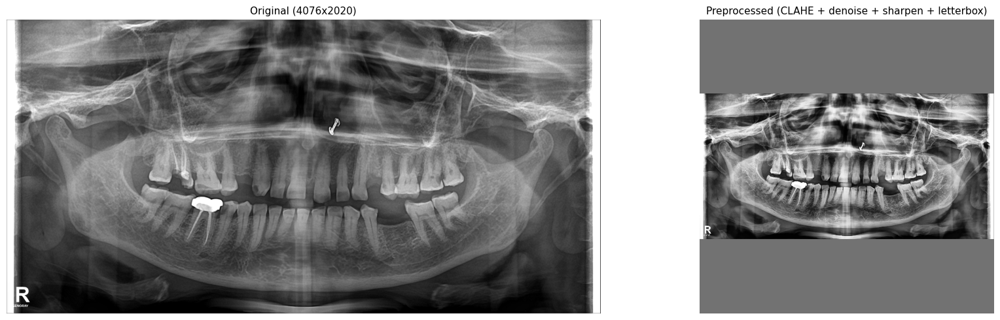


Detected 6 teeth:

  Tooth 18  conf=0.338  bbox=[968, 793, 1156, 1145]
  Tooth 21  conf=0.299  bbox=[2089, 753, 2237, 1268]
  Tooth 33  conf=0.373  bbox=[2300, 1262, 2428, 1633]
  Tooth 38  conf=0.281  bbox=[2911, 1161, 3193, 1492]
  Tooth 43  conf=0.397  bbox=[1640, 1251, 1798, 1703]
  Tooth 44  conf=0.266  bbox=[1523, 1237, 1688, 1709]


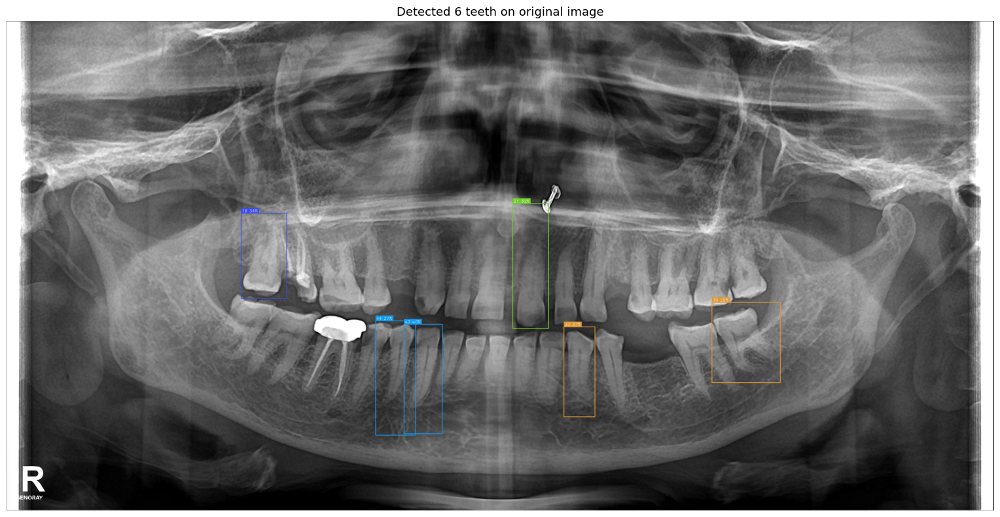


Saved to: /content/drive/MyDrive/dental_runs/predicted_result.jpg


In [ ]:
from google.colab import files
from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

valid_ext = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
if not img_path.lower().endswith(valid_ext):
    print(f"ERROR: Upload a JPG or PNG image, not a {Path(img_path).suffix} file.")
else:
    # Load original for display
    orig_img = cv2.imread(img_path)
    orig_H, orig_W = orig_img.shape[:2]

    # Preprocess
    preprocessed, (scale, top, left) = preprocess_opg(img_path, target_size=640)

    # Save preprocessed temp file for YOLO
    pre_path = '/content/preprocessed_input.jpg'
    cv2.imwrite(pre_path, preprocessed)

    # Show before/after
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5))
    ax1.imshow(cv2.cvtColor(orig_img,     cv2.COLOR_BGR2RGB), cmap='gray')
    ax1.set_title(f"Original ({orig_W}x{orig_H})", fontsize=11)
    ax1.axis('off')
    ax2.imshow(cv2.cvtColor(preprocessed, cv2.COLOR_BGR2RGB), cmap='gray')
    ax2.set_title("Preprocessed (CLAHE + denoise + sharpen + letterbox)", fontsize=11)
    ax2.axis('off')
    plt.tight_layout()
    plt.show()

    # Predict on preprocessed image
    res = model.predict(
        pre_path,
        conf    = 0.25,    # lower — catches more teeth after preprocessing
        iou     = 0.3,
        imgsz   = 640,
        save    = False,
        verbose = False,
    )[0]

    # Rescale boxes back to original image coordinates
    raw_boxes = [b.xyxy[0].tolist() for b in res.boxes]
    orig_boxes = rescale_boxes(raw_boxes, scale, top, left, orig_H, orig_W)

    # Print results
    print(f"\nDetected {len(res.boxes)} teeth:\n")
    detected = []
    for box_orig, b in zip(orig_boxes, res.boxes):
        fdi  = FDI_NAMES[int(b.cls)]
        conf = round(float(b.conf), 3)
        detected.append((fdi, conf, box_orig))

    detected.sort(key=lambda x: int(x[0]))
    for fdi, conf, bbox in detected:
        print(f"  Tooth {fdi}  conf={conf}  bbox={bbox}")

    # Draw on ORIGINAL image (not preprocessed)
    quadrant_colors = {
        '1': (231, 76,  60),
        '2': (46,  204, 113),
        '3': (52,  152, 219),
        '4': (243, 156, 18),
    }

    result_img = orig_img.copy()
    for fdi, conf, (x1, y1, x2, y2) in detected:
        color = quadrant_colors.get(fdi[0], (255, 255, 255))
        cv2.rectangle(result_img, (x1, y1), (x2, y2), color, 2)
        label = f"{fdi} {conf:.0%}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 1)
        cv2.rectangle(result_img, (x1, y1-th-8), (x1+tw+6, y1), color, -1)
        cv2.putText(result_img, label, (x1+3, y1-4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255,255,255), 1)

    # Save and display
    out_path = '/content/drive/MyDrive/dental_runs/predicted_result.jpg'
    cv2.imwrite(out_path, result_img)

    plt.figure(figsize=(18, 8))
    plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Detected {len(detected)} teeth on original image", fontsize=13)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    print(f"\nSaved to: {out_path}")

In [ ]:
import cv2
import numpy as np

def preprocess_opg_v2(img_path, target_size=640):
    """
    Stronger preprocessing pipeline for real clinical OPG scans.
    Addresses domain gap between Roboflow training data and real scanners.
    """
    img = cv2.imread(img_path)
    if img is None:
        raise ValueError(f"Cannot read: {img_path}")

    gray  = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    H, W  = gray.shape
    print(f"Original size: {W}x{H}")

    # ── Step 1: Remove dark border/background ──
    # Real OPGs have large black borders — crop to actual content
    _, thresh = cv2.threshold(gray, 15, 255, cv2.THRESH_BINARY)
    coords    = cv2.findNonZero(thresh)
    if coords is not None:
        x, y, w, h = cv2.boundingRect(coords)
        # Add 10px padding
        x  = max(0, x - 10)
        y  = max(0, y - 10)
        w  = min(W - x, w + 20)
        h  = min(H - y, h + 20)
        gray = gray[y:y+h, x:x+w]
        H, W = gray.shape
        print(f"After crop   : {W}x{H}")

    # ── Step 2: Gamma correction ──
    # Brightens dark teeth without blowing out bright areas
    gamma      = 1.4
    lut        = np.array([
        min(255, int((i / 255.0) ** (1.0 / gamma) * 255))
        for i in range(256)
    ], dtype=np.uint8)
    gamma_img  = cv2.LUT(gray, lut)

    # ── Step 3: CLAHE (stronger than before) ──
    clahe     = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    enhanced  = clahe.apply(gamma_img)

    # ── Step 4: Bilateral filter ──
    # Smooths noise but KEEPS tooth edges sharp
    filtered  = cv2.bilateralFilter(enhanced, d=9,
                                    sigmaColor=75, sigmaSpace=75)

    # ── Step 5: Unsharp mask (sharpen edges) ──
    blurred   = cv2.GaussianBlur(filtered, (0, 0), 3)
    sharpened = cv2.addWeighted(filtered, 1.8, blurred, -0.8, 0)

    # ── Step 6: Normalize to full 0-255 range ──
    normalized = cv2.normalize(sharpened, None, 0, 255, cv2.NORM_MINMAX)

    # ── Step 7: Letterbox resize (NO stretch) ──
    scale    = target_size / max(H, W)
    new_H    = int(H * scale)
    new_W    = int(W * scale)
    resized  = cv2.resize(normalized, (new_W, new_H),
                          interpolation=cv2.INTER_LANCZOS4)

    pad_H    = target_size - new_H
    pad_W    = target_size - new_W
    top      = pad_H // 2
    bottom   = pad_H - top
    left_pad = pad_W // 2
    right_pad= pad_W - left_pad

    padded   = cv2.copyMakeBorder(
        resized, top, bottom, left_pad, right_pad,
        cv2.BORDER_CONSTANT, value=114
    )

    final    = cv2.cvtColor(padded, cv2.COLOR_GRAY2BGR)

    return final, (scale, top, left_pad, H, W)


def predict_on_real_opg(img_path, model, fdi_names,
                        conf=0.2, target_size=640):
    """
    Full pipeline: preprocess → predict → rescale boxes → visualize
    """
    # Load original for display
    orig     = cv2.imread(img_path)
    orig_H, orig_W = orig.shape[:2]

    # Preprocess
    preprocessed, (scale, top, left_pad, crop_H, crop_W) = \
        preprocess_opg_v2(img_path, target_size)

    # Show before / after preprocessing
    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    axes[0].imshow(cv2.cvtColor(orig,         cv2.COLOR_BGR2RGB), cmap='gray')
    axes[0].set_title(f"Original  {orig_W}x{orig_H}", fontsize=11)
    axes[0].axis('off')
    axes[1].imshow(cv2.cvtColor(preprocessed, cv2.COLOR_BGR2RGB), cmap='gray')
    axes[1].set_title("Preprocessed (gamma + CLAHE + sharpen + letterbox)", fontsize=11)
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()

    # Save preprocessed for YOLO
    pre_path = '/content/preprocessed_v2.jpg'
    cv2.imwrite(pre_path, preprocessed)

    # Try multiple conf thresholds — pick best
    best_count = 0
    best_conf  = conf
    print("\nScanning confidence thresholds:")
    for c in [0.15, 0.2, 0.25, 0.3, 0.35]:
        r     = model.predict(pre_path, conf=c,
                              iou=0.3, imgsz=target_size,
                              verbose=False)[0]
        count = len(r.boxes)
        print(f"  conf={c}  →  {count} teeth  "
              f"{sorted([fdi_names[int(b.cls)] for b in r.boxes], key=int)}")
        if count > best_count:
            best_count = count
            best_conf  = c

    print(f"\nBest conf={best_conf} → {best_count} teeth detected")

    # Final prediction with best conf
    res = model.predict(
        pre_path,
        conf    = best_conf,
        iou     = 0.3,
        imgsz   = target_size,
        verbose = False,
    )[0]

    # Rescale boxes back to original image size
    detections = []
    for box in res.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        # Remove letterbox padding
        x1 = (x1 - left_pad) / scale
        y1 = (y1 - top)      / scale
        x2 = (x2 - left_pad) / scale
        y2 = (y2 - top)      / scale

        # Clamp to original bounds
        x1 = max(0, min(orig_W, x1))
        y1 = max(0, min(orig_H, y1))
        x2 = max(0, min(orig_W, x2))
        y2 = max(0, min(orig_H, y2))

        fdi  = fdi_names[int(box.cls)]
        conf_val = round(float(box.conf), 3)
        detections.append({
            'fdi'       : fdi,
            'confidence': conf_val,
            'bbox'      : [round(x1), round(y1),
                           round(x2), round(y2)],
            'quadrant'  : fdi[0],
        })

    detections.sort(key=lambda x: int(x['fdi']))
    return detections, orig


def visualize_on_original(orig_img, detections, save_path=None):
    """Draw detections on the original full-resolution image."""

    quadrant_colors = {
        '1': (231, 76,  60),    # red    — upper right
        '2': (46,  204, 113),   # green  — upper left
        '3': (52,  152, 219),   # blue   — lower left
        '4': (243, 156, 18),    # orange — lower right
    }

    result = orig_img.copy()

    for d in detections:
        x1, y1, x2, y2 = d['bbox']
        color = quadrant_colors.get(d['quadrant'], (255,255,255))
        label = f"{d['fdi']} {d['confidence']:.0%}"

        # Box
        cv2.rectangle(result, (x1,y1), (x2,y2), color, 2)

        # Label background + text
        (tw, th), _ = cv2.getTextSize(
            label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
        cv2.rectangle(result,
                      (x1, max(0, y1-th-10)),
                      (x1+tw+8, y1), color, -1)
        cv2.putText(result, label,
                    (x1+4, max(th, y1-4)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (255,255,255), 1)

    # Display
    scale_disp = 1200 / result.shape[1]
    disp       = cv2.resize(result,
                            (1200, int(result.shape[0]*scale_disp)))

    plt.figure(figsize=(18, 8))
    plt.imshow(cv2.cvtColor(disp, cv2.COLOR_BGR2RGB))
    plt.title(f"Detected {len(detections)} teeth  |  "
              f"Quadrants: "
              f"Q1={sum(1 for d in detections if d['quadrant']=='1')}  "
              f"Q2={sum(1 for d in detections if d['quadrant']=='2')}  "
              f"Q3={sum(1 for d in detections if d['quadrant']=='3')}  "
              f"Q4={sum(1 for d in detections if d['quadrant']=='4')}",
              fontsize=12)
    plt.axis('off')
    plt.tight_layout()

    if save_path:
        cv2.imwrite(save_path, result)
        print(f"Saved: {save_path}")
    plt.show()

Saving 502a6efb-20230419-142144419.jpg to 502a6efb-20230419-142144419.jpg
Original size: 4076x2020
After crop   : 4076x2020


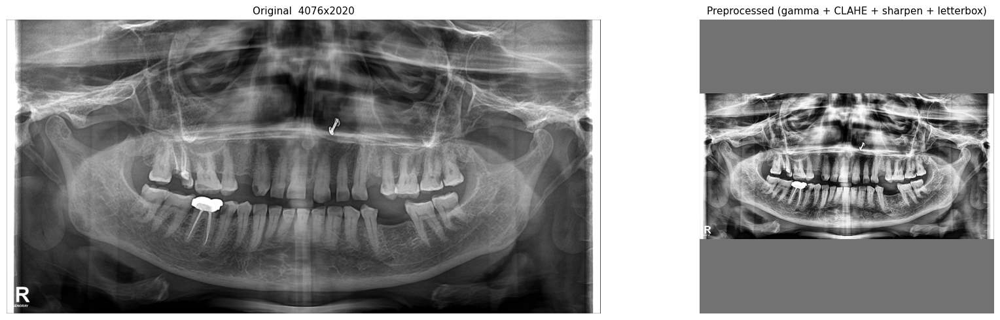


Scanning confidence thresholds:
  conf=0.15  →  18 teeth  ['11', '11', '13', '15', '16', '17', '18', '18', '18', '21', '21', '22', '22', '23', '31', '41', '43', '48']
  conf=0.2  →  9 teeth  ['11', '16', '18', '18', '21', '21', '22', '22', '48']
  conf=0.25  →  4 teeth  ['18', '21', '21', '48']
  conf=0.3  →  4 teeth  ['18', '21', '21', '48']
  conf=0.35  →  2 teeth  ['18', '21']

Best conf=0.15 → 18 teeth detected

Detected 18 teeth:

  Tooth 11  conf=0.202
  Tooth 11  conf=0.184
  Tooth 13  conf=0.181
  Tooth 15  conf=0.185
  Tooth 16  conf=0.201
  Tooth 17  conf=0.181
  Tooth 18  conf=0.547
  Tooth 18  conf=0.238
  Tooth 18  conf=0.151
  Tooth 21  conf=0.485
  Tooth 21  conf=0.314
  Tooth 22  conf=0.245
  Tooth 22  conf=0.223
  Tooth 23  conf=0.16
  Tooth 31  conf=0.176
  Tooth 41  conf=0.154
  Tooth 43  conf=0.174
  Tooth 48  conf=0.304

Quadrant summary:
  Q1 Upper Right  → ['11', '11', '13', '15', '16', '17', '18', '18', '18']
  Q2 Upper Left   → ['21', '21', '22', '22', '23']
 

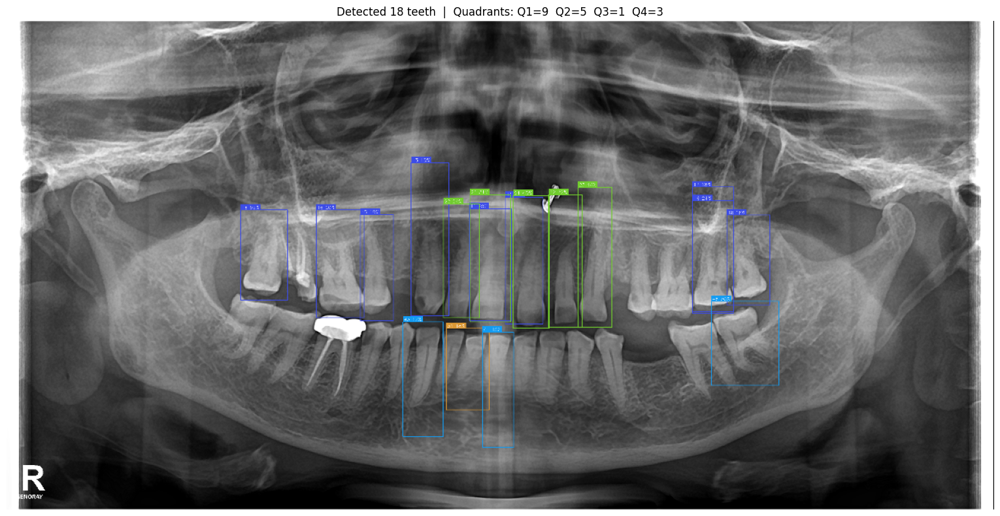

In [ ]:
from google.colab import files
import matplotlib.pyplot as plt

# Load your best model
model = YOLO('/content/drive/MyDrive/dental_runs/opg_v1/weights/best.pt')

# Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# Run full pipeline
detections, orig_img = predict_on_real_opg(
    img_path, model, FDI_NAMES, conf=0.2
)

# Print results
print(f"\nDetected {len(detections)} teeth:\n")
q_teeth = {'1':[], '2':[], '3':[], '4':[]}
for d in detections:
    print(f"  Tooth {d['fdi']}  conf={d['confidence']}")
    q_teeth[d['quadrant']].append(d['fdi'])

print(f"\nQuadrant summary:")
labels = {'1':'Upper Right','2':'Upper Left',
          '3':'Lower Left', '4':'Lower Right'}
for q in ['1','2','3','4']:
    print(f"  Q{q} {labels[q]:12s} → "
          f"{q_teeth[q] if q_teeth[q] else 'none detected'}")

# Visualize
visualize_on_original(
    orig_img, detections,
    save_path='/content/drive/MyDrive/dental_runs/result_v2.jpg'
)

In [ ]:
def boost_upper_jaw(gray_img):
    """
    Boost brightness of top half of image where upper teeth are.
    Upper teeth are often underexposed in OPG scans.
    """
    H, W  = gray_img.shape
    upper = gray_img[:H//2, :]   # top half
    lower = gray_img[H//2:, :]   # bottom half

    # Apply stronger CLAHE to upper region only
    clahe_strong = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(4, 4))
    upper_boost  = clahe_strong.apply(upper)

    # Mild CLAHE for lower (already more visible)
    clahe_mild   = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    lower_boost  = clahe_mild.apply(lower)

    return np.vstack([upper_boost, lower_boost])

In [ ]:
import cv2
import numpy as np
from ultralytics import YOLO

def predict_tiled(img_path, model, fdi_names,
                  tile_size=640, overlap=0.3, conf=0.2):
    """
    Split OPG into overlapping tiles, predict on each,
    then merge with WBF. Fixes edge teeth being missed.
    """
    from ensemble_boxes import weighted_boxes_fusion

    orig   = cv2.imread(img_path)
    orig_H, orig_W = orig.shape[:2]

    # Preprocess full image first
    preprocessed, (scale, top, left_pad, crop_H, crop_W) = \
        preprocess_opg_v2(img_path, target_size=1280)

    pre_H, pre_W = preprocessed.shape[:2]

    # Calculate tile positions with overlap
    step    = int(tile_size * (1 - overlap))
    tiles   = []

    for y in range(0, pre_H - tile_size + step, step):
        for x in range(0, pre_W - tile_size + step, step):
            x2 = min(x + tile_size, pre_W)
            y2 = min(y + tile_size, pre_H)
            x1_t = x2 - tile_size
            y1_t = y2 - tile_size
            tiles.append((max(0, x1_t), max(0, y1_t), x2, y2))

    print(f"Predicting on {len(tiles)} tiles...")

    all_boxes, all_scores, all_labels = [], [], []

    for (tx1, ty1, tx2, ty2) in tiles:
        tile     = preprocessed[ty1:ty2, tx1:tx2]
        tile_pad = np.ones((tile_size, tile_size, 3),
                           dtype=np.uint8) * 114
        th, tw   = tile.shape[:2]
        tile_pad[:th, :tw] = tile

        # Save tile temp
        tile_path = '/content/tmp_tile.jpg'
        cv2.imwrite(tile_path, tile_pad)

        res = model.predict(
            tile_path, conf=conf,
            iou=0.3, verbose=False
        )[0]

        for box in res.boxes:
            bx1, by1, bx2, by2 = box.xyxy[0].tolist()

            # Convert tile coords → full preprocessed image coords
            bx1 += tx1;  bx2 += tx1
            by1 += ty1;  by2 += ty1

            # Normalize to 0-1
            all_boxes.append([
                bx1/pre_W, by1/pre_H,
                bx2/pre_W, by2/pre_H
            ])
            all_scores.append(float(box.conf))
            all_labels.append(int(box.cls))

    if not all_boxes:
        print("No teeth detected in any tile")
        return [], orig

    # Merge all tile predictions with WBF
    fused_boxes, fused_scores, fused_labels = weighted_boxes_fusion(
        [all_boxes], [all_scores], [all_labels],
        iou_thr      = 0.4,
        skip_box_thr = 0.2,
    )

    # Rescale back to original image coords
    detections = []
    for box, score, label in zip(fused_boxes, fused_scores, fused_labels):
        cls_id = int(round(label))
        if cls_id >= len(fdi_names):
            continue

        # Preprocessed → original coords
        x1 = (box[0] * pre_W - left_pad) / scale
        y1 = (box[1] * pre_H - top)      / scale
        x2 = (box[2] * pre_W - left_pad) / scale
        y2 = (box[3] * pre_H - top)      / scale

        x1 = max(0, min(orig_W, x1))
        y1 = max(0, min(orig_H, y1))
        x2 = max(0, min(orig_W, x2))
        y2 = max(0, min(orig_H, y2))

        detections.append({
            'fdi'       : fdi_names[cls_id],
            'confidence': round(float(score), 3),
            'bbox'      : [round(x1), round(y1),
                           round(x2), round(y2)],
            'quadrant'  : fdi_names[cls_id][0],
        })

    detections.sort(key=lambda x: int(x['fdi']))
    print(f"Final merged: {len(detections)} teeth detected")
    return detections, orig

In [ ]:
# ── Run tiled prediction ──
from google.colab import files
import matplotlib.pyplot as plt

model = YOLO('/content/drive/MyDrive/dental_runs/opg_v1/weights/best.pt')

uploaded  = files.upload()
img_path  = list(uploaded.keys())[0]

detections, orig_img = predict_tiled(
    img_path, model, FDI_NAMES,
    tile_size = 640,
    overlap   = 0.3,
    conf      = 0.2,
)

# Print results
print(f"\nDetected {len(detections)} teeth:\n")
q_teeth = {'1':[], '2':[], '3':[], '4':[]}
for d in detections:
    print(f"  Tooth {d['fdi']}  conf={d['confidence']}")
    q_teeth[d['quadrant']].append(d['fdi'])

print(f"\nQuadrant summary:")
names_q = {'1':'Upper Right','2':'Upper Left',
           '3':'Lower Left', '4':'Lower Right'}
for q in ['1','2','3','4']:
    missing = [t for t in FDI_NAMES
               if t[0]==q and t not in q_teeth[q]]
    print(f"  Q{q} {names_q[q]:12s} → "
          f"detected={q_teeth[q]}  "
          f"missing={missing if missing else 'none'}")

# Visualize
visualize_on_original(
    orig_img, detections,
    save_path='/content/drive/MyDrive/dental_runs/tiled_result.jpg'
)

Saving 502a6efb-20230419-142144419.jpg to 502a6efb-20230419-142144419.jpg


ModuleNotFoundError: No module named 'ensemble_boxes'

In [ ]:
def predict_tiled_fixed(img_path, model, fdi_names,
                        tile_size=640, overlap=0.25, conf=0.3):
    """
    Fixed version — much stricter merging to prevent duplicate detections.
    """
    from ensemble_boxes import weighted_boxes_fusion

    orig   = cv2.imread(img_path)
    orig_H, orig_W = orig.shape[:2]

    preprocessed, (scale, top, left_pad, crop_H, crop_W) = \
        preprocess_opg_v2(img_path, target_size=1280)

    pre_H, pre_W = preprocessed.shape[:2]

    step  = int(tile_size * (1 - overlap))
    tiles = []
    for y in range(0, pre_H - tile_size + step, step):
        for x in range(0, pre_W - tile_size + step, step):
            x2 = min(x + tile_size, pre_W)
            y2 = min(y + tile_size, pre_H)
            x1_t = x2 - tile_size
            y1_t = y2 - tile_size
            tiles.append((max(0, x1_t), max(0, y1_t), x2, y2))

    print(f"Predicting on {len(tiles)} tiles...")

    all_boxes, all_scores, all_labels = [], [], []

    for (tx1, ty1, tx2, ty2) in tiles:
        tile     = preprocessed[ty1:ty2, tx1:tx2]
        tile_pad = np.ones((tile_size, tile_size, 3), dtype=np.uint8) * 114
        th, tw   = tile.shape[:2]
        tile_pad[:th, :tw] = tile

        tile_path = '/content/tmp_tile.jpg'
        cv2.imwrite(tile_path, tile_pad)

        res = model.predict(
            tile_path, conf=conf,
            iou=0.4, verbose=False,
            agnostic_nms=True,    # NMS within each tile first
        )[0]

        for box in res.boxes:
            bx1, by1, bx2, by2 = box.xyxy[0].tolist()
            bx1 += tx1;  bx2 += tx1
            by1 += ty1;  by2 += ty1
            all_boxes.append([bx1/pre_W, by1/pre_H, bx2/pre_W, by2/pre_H])
            all_scores.append(float(box.conf))
            all_labels.append(int(box.cls))

    if not all_boxes:
        return [], orig

    # ── Much stricter WBF merging ──
    fused_boxes, fused_scores, fused_labels = weighted_boxes_fusion(
        [all_boxes], [all_scores], [all_labels],
        iou_thr      = 0.25,   # LOWER = merges boxes that overlap even slightly
        skip_box_thr = 0.35,   # HIGHER = removes weak duplicate boxes
    )

    # Rescale to original
    detections = []
    for box, score, label in zip(fused_boxes, fused_scores, fused_labels):
        cls_id = int(round(label))
        if cls_id >= len(fdi_names):
            continue
        x1 = (box[0]*pre_W - left_pad) / scale
        y1 = (box[1]*pre_H - top)      / scale
        x2 = (box[2]*pre_W - left_pad) / scale
        y2 = (box[3]*pre_H - top)      / scale
        x1=max(0,min(orig_W,x1)); y1=max(0,min(orig_H,y1))
        x2=max(0,min(orig_W,x2)); y2=max(0,min(orig_H,y2))
        detections.append({
            'fdi': fdi_names[cls_id], 'confidence': round(float(score),3),
            'bbox':[round(x1),round(y1),round(x2),round(y2)],
            'quadrant': fdi_names[cls_id][0],
        })

    # ── CRITICAL: Final cleanup — remove duplicate FDI numbers ──
    # A real mouth has only ONE of each tooth number (11, 12, ... 48)
    # Keep only the highest confidence box per FDI number
    best_per_fdi = {}
    for d in detections:
        fdi = d['fdi']
        if fdi not in best_per_fdi or d['confidence'] > best_per_fdi[fdi]['confidence']:
            best_per_fdi[fdi] = d

    final_detections = sorted(best_per_fdi.values(), key=lambda x: int(x['fdi']))

    print(f"Before dedup: {len(detections)} boxes")
    print(f"After dedup : {len(final_detections)} unique teeth")

    return final_detections, orig

In [ ]:
!pip install ensemble-boxes -q

Original size: 4076x2020
After crop   : 4076x2020
Predicting on 9 tiles...
Before dedup: 19 boxes
After dedup : 14 unique teeth

Final: 14 unique teeth detected (max possible = 32)

  Tooth 11  conf=0.581
  Tooth 12  conf=0.597
  Tooth 13  conf=0.663
  Tooth 15  conf=0.782
  Tooth 16  conf=0.543
  Tooth 27  conf=0.44
  Tooth 34  conf=0.462
  Tooth 35  conf=0.697
  Tooth 36  conf=0.415
  Tooth 37  conf=0.437
  Tooth 38  conf=0.475
  Tooth 42  conf=0.392
  Tooth 46  conf=0.414
  Tooth 47  conf=0.632

Quadrant summary:
  Q1 Upper Right  → ['11', '12', '13', '15', '16']
  Q2 Upper Left   → ['27']
  Q3 Lower Left   → ['34', '35', '36', '37', '38']
  Q4 Lower Right  → ['42', '46', '47']
Saved: /content/drive/MyDrive/dental_runs/fixed_result.jpg


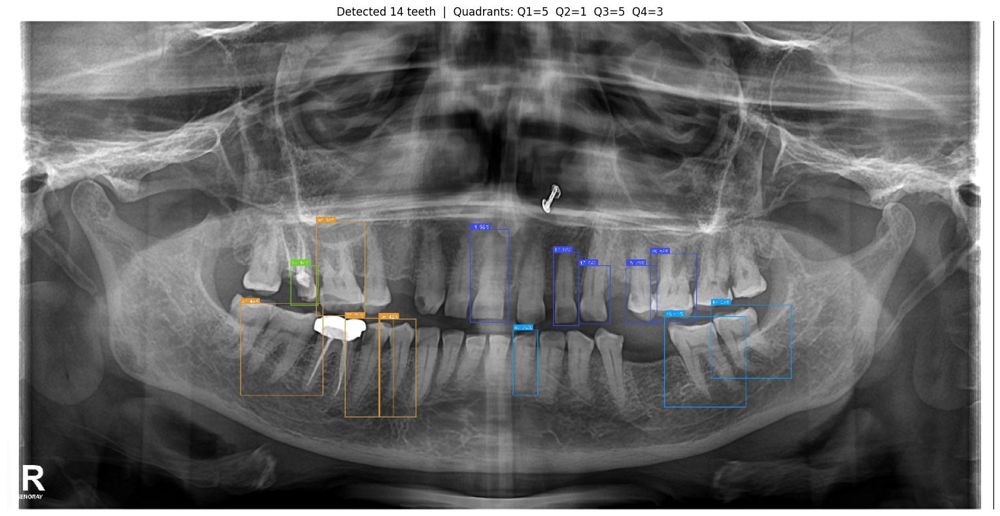

In [ ]:
detections, orig_img = predict_tiled_fixed(
    img_path, model, FDI_NAMES,
    tile_size = 640,
    overlap   = 0.25,
    conf      = 0.3,
)

print(f"\nFinal: {len(detections)} unique teeth detected (max possible = 32)\n")
q_teeth = {'1':[], '2':[], '3':[], '4':[]}
for d in detections:
    print(f"  Tooth {d['fdi']}  conf={d['confidence']}")
    q_teeth[d['quadrant']].append(d['fdi'])

print(f"\nQuadrant summary:")
names_q = {'1':'Upper Right','2':'Upper Left','3':'Lower Left','4':'Lower Right'}
for q in ['1','2','3','4']:
    print(f"  Q{q} {names_q[q]:12s} → {q_teeth[q]}")

visualize_on_original(orig_img, detections,
    save_path='/content/drive/MyDrive/dental_runs/fixed_result.jpg')

In [ ]:
def predict_tiled_balanced(img_path, model, fdi_names,
                           tile_size=640, overlap=0.25, conf=0.22):
    from ensemble_boxes import weighted_boxes_fusion

    orig   = cv2.imread(img_path)
    orig_H, orig_W = orig.shape[:2]

    preprocessed, (scale, top, left_pad, crop_H, crop_W) = \
        preprocess_opg_v2(img_path, target_size=1280)

    pre_H, pre_W = preprocessed.shape[:2]

    step  = int(tile_size * (1 - overlap))
    tiles = []
    for y in range(0, pre_H - tile_size + step, step):
        for x in range(0, pre_W - tile_size + step, step):
            x2 = min(x + tile_size, pre_W)
            y2 = min(y + tile_size, pre_H)
            x1_t = x2 - tile_size
            y1_t = y2 - tile_size
            tiles.append((max(0, x1_t), max(0, y1_t), x2, y2))

    print(f"Predicting on {len(tiles)} tiles...")

    all_boxes, all_scores, all_labels = [], [], []

    for (tx1, ty1, tx2, ty2) in tiles:
        tile     = preprocessed[ty1:ty2, tx1:tx2]
        tile_pad = np.ones((tile_size, tile_size, 3), dtype=np.uint8) * 114
        th, tw   = tile.shape[:2]
        tile_pad[:th, :tw] = tile
        tile_path = '/content/tmp_tile.jpg'
        cv2.imwrite(tile_path, tile_pad)

        res = model.predict(
            tile_path, conf=conf, iou=0.4,
            verbose=False, agnostic_nms=False,   # keep per-class NMS
        )[0]

        for box in res.boxes:
            bx1, by1, bx2, by2 = box.xyxy[0].tolist()
            bx1 += tx1;  bx2 += tx1
            by1 += ty1;  by2 += ty1
            all_boxes.append([bx1/pre_W, by1/pre_H, bx2/pre_W, by2/pre_H])
            all_scores.append(float(box.conf))
            all_labels.append(int(box.cls))

    if not all_boxes:
        return [], orig

    # ── KEY FIX: only fuse boxes of the SAME class ──
    # This stops WBF from merging two different adjacent teeth into one
    fused_boxes, fused_scores, fused_labels = weighted_boxes_fusion(
        [all_boxes], [all_scores], [all_labels],
        iou_thr      = 0.5,    # only merge if heavily overlapping (same tooth, different tile)
        skip_box_thr = 0.22,   # keep most real detections
    )

    detections = []
    for box, score, label in zip(fused_boxes, fused_scores, fused_labels):
        cls_id = int(round(label))
        if cls_id >= len(fdi_names):
            continue
        x1 = (box[0]*pre_W - left_pad) / scale
        y1 = (box[1]*pre_H - top)      / scale
        x2 = (box[2]*pre_W - left_pad) / scale
        y2 = (box[3]*pre_H - top)      / scale
        x1=max(0,min(orig_W,x1)); y1=max(0,min(orig_H,y1))
        x2=max(0,min(orig_W,x2)); y2=max(0,min(orig_H,y2))
        detections.append({
            'fdi': fdi_names[cls_id], 'confidence': round(float(score),3),
            'bbox':[round(x1),round(y1),round(x2),round(y2)],
            'quadrant': fdi_names[cls_id][0],
        })

    # Dedup: keep best box PER FDI NUMBER, but only if true duplicates
    # (same fdi AND boxes actually overlap significantly)
    def iou(b1, b2):
        x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
        x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
        inter = max(0, x2-x1) * max(0, y2-y1)
        area1 = (b1[2]-b1[0])*(b1[3]-b1[1])
        area2 = (b2[2]-b2[0])*(b2[3]-b2[1])
        union = area1 + area2 - inter
        return inter/union if union > 0 else 0

    detections.sort(key=lambda x: -x['confidence'])
    final = []
    for d in detections:
        is_dup = False
        for f in final:
            if f['fdi'] == d['fdi'] and iou(f['bbox'], d['bbox']) > 0.3:
                is_dup = True
                break
        if not is_dup:
            final.append(d)

    final.sort(key=lambda x: int(x['fdi']))
    print(f"Before dedup: {len(detections)} boxes")
    print(f"After dedup : {len(final)} unique teeth")
    return final, orig

Original size: 4076x2020
After crop   : 4076x2020
Predicting on 9 tiles...
Before dedup: 42 boxes
After dedup : 37 unique teeth

Final: 37 unique teeth

  Tooth 11  conf=0.639
  Tooth 11  conf=0.466
  Tooth 11  conf=0.29
  Tooth 12  conf=0.719
  Tooth 12  conf=0.238
  Tooth 13  conf=0.663
  Tooth 15  conf=0.782
  Tooth 16  conf=0.637
  Tooth 16  conf=0.428
  Tooth 17  conf=0.275
  Tooth 27  conf=0.44
  Tooth 34  conf=0.38
  Tooth 34  conf=0.291
  Tooth 35  conf=0.697
  Tooth 35  conf=0.301
  Tooth 35  conf=0.244
  Tooth 36  conf=0.415
  Tooth 37  conf=0.437
  Tooth 37  conf=0.312
  Tooth 37  conf=0.291
  Tooth 37  conf=0.286
  Tooth 37  conf=0.24
  Tooth 38  conf=0.425
  Tooth 38  conf=0.403
  Tooth 38  conf=0.365
  Tooth 38  conf=0.225
  Tooth 42  conf=0.377
  Tooth 42  conf=0.3
  Tooth 42  conf=0.293
  Tooth 43  conf=0.265
  Tooth 45  conf=0.281
  Tooth 46  conf=0.403
  Tooth 46  conf=0.354
  Tooth 47  conf=0.632
  Tooth 47  conf=0.458
  Tooth 47  conf=0.305
  Tooth 47  conf=0.258
  

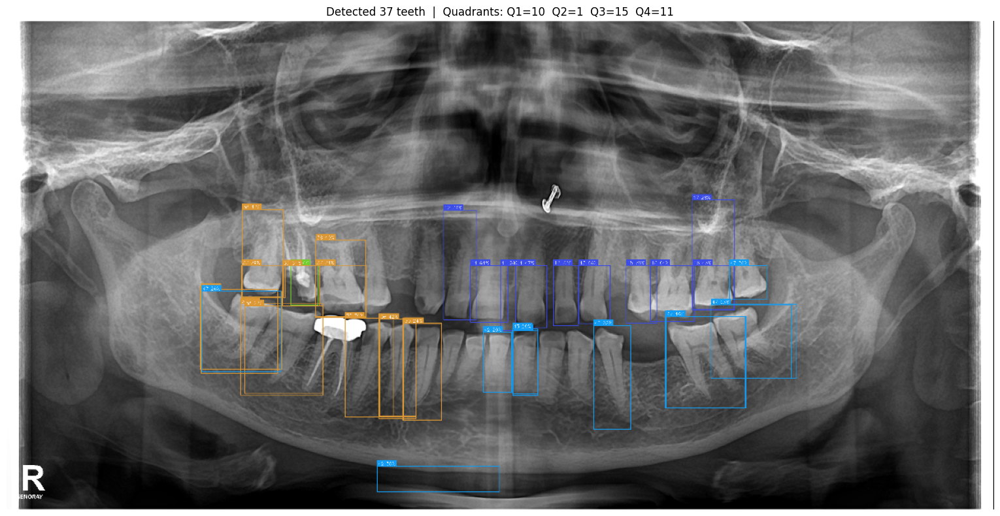

In [ ]:
# Run with balanced settings
detections, orig_img = predict_tiled_balanced(
    img_path, model, FDI_NAMES,
    tile_size = 640,
    overlap   = 0.25,
    conf      = 0.22,
)

print(f"\nFinal: {len(detections)} unique teeth\n")
q_teeth = {'1':[], '2':[], '3':[], '4':[]}
for d in detections:
    print(f"  Tooth {d['fdi']}  conf={d['confidence']}")
    q_teeth[d['quadrant']].append(d['fdi'])

names_q = {'1':'Upper Right','2':'Upper Left','3':'Lower Left','4':'Lower Right'}
for q in ['1','2','3','4']:
    print(f"  Q{q} {names_q[q]:12s} → {q_teeth[q]}")

visualize_on_original(orig_img, detections,
    save_path='/content/drive/MyDrive/dental_runs/balanced_result.jpg')

Original size: 4076x2020
After crop   : 4076x2020
Simple prediction: 19 teeth


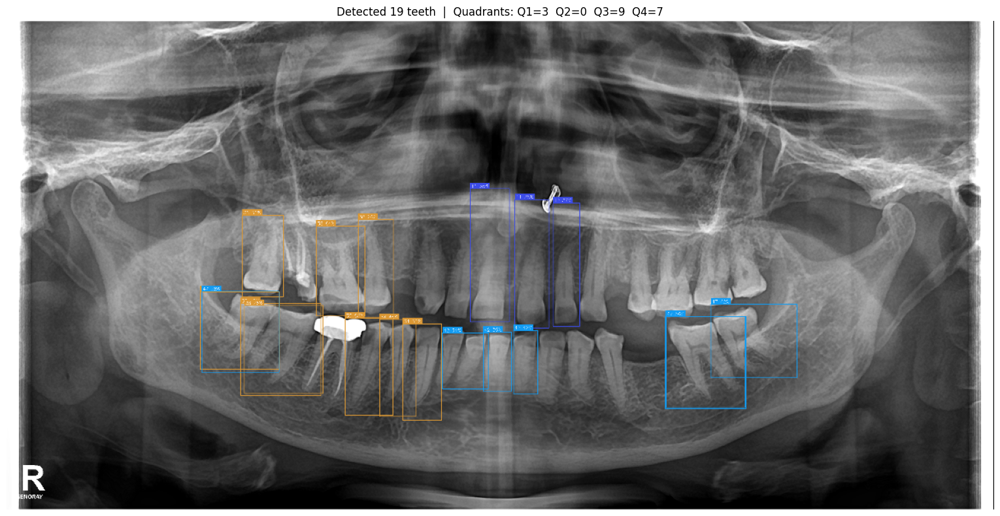

In [ ]:
# Simple single-pass prediction — no tiling, no WBF, no dedup hacks
def predict_simple(img_path, model, fdi_names, conf=0.25, imgsz=1280):
    preprocessed, (scale, top, left_pad, crop_H, crop_W) = \
        preprocess_opg_v2(img_path, target_size=imgsz)

    orig = cv2.imread(img_path)
    orig_H, orig_W = orig.shape[:2]

    pre_path = '/content/pre_simple.jpg'
    cv2.imwrite(pre_path, preprocessed)

    res = model.predict(pre_path, conf=conf, iou=0.4,
                        imgsz=imgsz, verbose=False)[0]

    detections = []
    for box in res.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        x1 = max(0, min(orig_W, (x1-left_pad)/scale))
        y1 = max(0, min(orig_H, (y1-top)/scale))
        x2 = max(0, min(orig_W, (x2-left_pad)/scale))
        y2 = max(0, min(orig_H, (y2-top)/scale))
        fdi = fdi_names[int(box.cls)]
        detections.append({
            'fdi': fdi, 'confidence': round(float(box.conf),3),
            'bbox':[round(x1),round(y1),round(x2),round(y2)],
            'quadrant': fdi[0],
        })

    detections.sort(key=lambda x: int(x['fdi']))
    return detections, orig

detections, orig_img = predict_simple(img_path, model, FDI_NAMES, conf=0.25)
print(f"Simple prediction: {len(detections)} teeth")
visualize_on_original(orig_img, detections)